In [ ]:
# rsync -av --progress /scratch/franzihe/input/COMBLE u6030275@notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data 

# rsync -av --progress login.nird.sigma2.no:/projects/NS9600K/data/Met-No_obs/  /uio/kant/geo-metos-u1/franzihe/Documents/input/Met-No_obs

In [ ]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/"
if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"

INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

# make output file directory
nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')
try:
    new_dir = pathlib.Path(nc_dir)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

mimi.uio.no


## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [ ]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt, np, DateFormatter, datetime, cm, pd, da, IMProToo,LinearSegmentedColormap, BoundaryNorm, time, curve_fit, sns, set_context)
# from matplotlib.collections import PathCollection
import functions as fct
version = IMProToo.__version__


In [ ]:
# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [ ]:
# reload imports
%load_ext autoreload
%autoreload 2

In [ ]:
sites = ["ANX", ]#"ALOMAR"]
years = [#"2021","2022",
         "2023"]

In [ ]:
mrr_in_dict, ds_dict_mrr = {}, {}
met_dict_t, met_dict_wd, met_dict_ws, met_dict_p = {}, {}, {}, {}
ds_dict_met_t, ds_dict_met_wd, ds_dict_met_ws, ds_dict_met_p = {}, {}, {}, {}
# ceil_in_dict, ds_dict_ceil = {}, {}
snowflake_class_in_dict, ds_dict_snowflake_class = {}, {}
# graupel_in_dict, ds_dict_graupel = {}, {}
# aggregate_in_dict, ds_dict_aggregate = {}, {}
# small_particle_in_dict, ds_dict_small_particle = {}, {}
# planar_crystal_in_dict, ds_dict_planar_crystal = {}, {}
# columnar_crystal_in_dict, ds_dict_columnar_crystal = {}, {}
# columnar_planar_in_dict, ds_dict_columnar_planar = {}, {}


In [ ]:
dicts_to_clean = [ds_dict_mrr,#ds_dict_ceil, 
                  ds_dict_snowflake_class, ds_dict_met_t,ds_dict_met_wd,ds_dict_met_ws,ds_dict_met_p]

In [ ]:
met_no_dict = {}
ds_dict_metno = {}



for site in sites:
    for year in years:
        key = f'{site}.{year}'
        
        # Collect file paths
        mrr_in_dict[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'MRR_ANX/maahn/mrr_improtoo*_{site}_{year}*.nc')))
        # ceil_in_dict[key]   = sorted(glob(os.path.join(INPUT_DATA_DIR, f'ceilometer/combined/bsc_cbh_{year}*.nc')))
        snowflake_class_in_dict[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'MASC_DB/t_2degC/*{year}_most_common_class_1min_0.6.nc')))

        # hatpro_in_dict[f'{site}.{year}'] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/{year}/*/*/*{year}*.nc')))
        
        # Met data handling
        # met_no_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*{}*'.format(year))))
        if year in ["2021",]:
            met_dict_t[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/air_temperature_{year}*.nc')))
        if year == "2022":
            met_dict_t[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'tinytag/TGP-4505_917173.nc')))
        if year == "2023":
            met_dict_t[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/hatpro_new_20240716/level1/{year}/*/*/*.nc')))
            # # met_dict_wd[key]   = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/hatpro_new_20240716/level1/{year}/*/*/*.nc')))
            # # met_dict_ws[key]   = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/hatpro_new_20240716/level1/{year}/*/*/*.nc')))
            # # met_dict_t[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/air_temperature_{year}*.nc')))
            met_dict_wd[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/ANX_wind_10min_to_1min_filled_{year}.nc')))
            met_dict_ws[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/ANX_wind_10min_to_1min_filled_{year}.nc')))
            met_dict_p[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'geonor/precip_*.nc')))
        if year in ['2021', '2022',]:
            met_dict_wd[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/wind_from_direction_{year}*.nc')))
            met_dict_ws[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/wind_speed_{year}*.nc')))
            met_dict_p[key]  = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/*sum(precipitation_amount PT1H)_{year}*')))
        
        # Open or initialize Datasets
        ds_dict_mrr[key]        = fct.open_or_empty(mrr_in_dict[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        # ds_dict_ceil[key]       = fct.open_or_empty(ceil_in_dict[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_snowflake_class[key] = fct.open_or_empty(snowflake_class_in_dict[key], decode_times=True, preprocess=lambda x: x.sortby('time'))

        ds_dict_met_t[key]      = fct.open_or_empty(met_dict_t[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_met_wd[key]     = fct.open_or_empty(met_dict_wd[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_met_ws[key]     = fct.open_or_empty(met_dict_ws[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_met_p[key]      = fct.open_or_empty(met_dict_p[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        
        
        # for ds_dict in dicts_to_clean:
        #     if key in ds_dict: # just in case key is missing
        #         ds = ds_dict[key].copy()
        #         if 'time' in ds.dims and ds.sizes['time'] > 0:
        #             ds_dict[key] = ds.dropna(dim='time')
        # #             ds_dict[key] = ds.sel(time=~ds.indexes['time'].duplicated('first'))
        

In [ ]:
base_height = np.arange(100,3200, 100) # Predefined MRR profile


In [ ]:
# target_dates = {'20210317',}# '20220322', '20230225'}
# target_dates = {'20230215', '20230216','20230217','20230218','20230219','20230220','20230221','20230222','20230223','20230224','20230225','20230226','20230227','20230228','20230301','20230302','20230303','20230305','20230306','20230307','20230308','20230309','20230310','20230311','20230312','20230313','20230314'}
target_dates = {'20230301',}
start = time.time()
for key in list(mrr_in_dict.keys()):
    site, year = key.split('.')
    
    for j, file_path in enumerate(mrr_in_dict[key]):
        date = file_path[-11:-3]
        # if date not in target_dates:
        #     continue  # Skip dates not in the target list
        
        
        
        print(f"Reading file for {site}, {date}...")
        figname = f'mrr_reflectivity_{site}_{date}.png'
        # file_out = os.path.join(OUTPUT_DATA_DIR, f'MRR_ANX/bin_averaged/mrr_improtoo_{version}_{site}_{date}.nc')
        # pathlib.Path(os.path.dirname(file_out)).mkdir(parents=True, exist_ok=True)
        
        # filename = f"obs_{site}_{date}.nc"
        # filename = f"obs_airport_WD_WS_T_{site}_{date}.nc"
        # filename = f"obs_hatpro_airport_WD_WS_T_{site}_{date}.nc"
        filename = f"10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{date}.nc"
        
        # Define start and end time of individual day
        day_start = pd.Timestamp(f"{date} 00:00:00")
        day_end = day_start + pd.Timedelta(hours=23, minutes=59)
        _xmax = day_start + pd.Timedelta(hours=24)
        _time = pd.date_range(start=day_start, periods=1440, freq='min')
        # Create 5-min interval time range for that day
        times = pd.date_range(start=day_start, end=day_end, freq='5min', )#closed='left')

        # create new dataset with NaNs and time resolution 1 minute
        dsx = xr.Dataset(data_vars=dict(
            air_temperature =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            wind_direction  =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            wind_speed      =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            precipitation   =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            Ze              =(["time","range"], da.full(shape= (len(_time),len(ds_dict_mrr[key].range)), fill_value = np.nan)),
            W               =(["time","range"], da.full(shape= (len(_time),len(ds_dict_mrr[key].range)), fill_value = np.nan)),
            height          =(["range"], base_height),
            spectralWidth   =(["time","range"], da.full(shape= (len(_time),len(ds_dict_mrr[key].range)), fill_value = np.nan)),
            # bsc             =(["time","altitude"], da.full(shape=(len(_time), len(ds_dict_ceil[key].altitude)), fill_value=np.nan)),
            # cbh             =(["time"], np.full(shape=(len(_time),), fill_value=np.nan)),
            most_common_class = (["time"], np.full(shape=(len(_time),), fill_value=np.nan, dtype=object)),
            aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            graupel = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            pristine = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            mixed = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            wind_sector_8 = (["time"], np.full(shape=(len(_time),), fill_value=np.nan, dtype=object)),
            wind_sector_16 = (["time"], np.full(shape=(len(_time),), fill_value=np.nan, dtype=object)),
            riming_deg_level = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Matrosov_aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Bracci_aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Nakai_aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Nakai_graupel = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Pu_graupel = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
        ),
                         coords=dict(
                             time       =_time,
                             range      =ds_dict_mrr[key].range.values,
                            #  altitude   =ds_dict_ceil[key].altitude.values
                             ))
        

        
# Variable names per year
        # if year in ['2021', '2022', '2023']:
        if year == '2021':
                var_id_t    = 'air_temperature'
                var_id_wd   = 'wind_from_direction'
                var_id_pp   = 'sum(precipitation_amount PT1H)'
                var_id_ws   = 'wind_speed'
        elif year == '2022':
                var_id_t    = 'TA'
                var_id_wd   = 'wind_from_direction'
                var_id_pp   = 'sum(precipitation_amount PT1H)'
                var_id_ws   = 'wind_speed'
        elif year == '2023':
                var_id_t    = 'air_temperature'
                # var_id_wd   = 'wind_direction'
                var_id_wd   = 'wind_direction_filled'
                var_id_pp   = 'precipitation'
                var_id_ws   = 'wind_speed_filled'
        _air_temp   = ds_dict_met_t[key][var_id_t].sel(time = slice(day_start, day_end))
        _wd         = ds_dict_met_wd[key][var_id_wd].sel(time = slice(day_start, day_end))
        _ws         = ds_dict_met_ws[key][var_id_ws].sel(time = slice(day_start, day_end))
        _pp         = ds_dict_met_p[key][var_id_pp].sel(time = slice(day_start, day_end))
        # elif year in ['2023']:
        #     _air_temp   = ds_dict_snowflake_class[key]['env_T_test'].sel(time = slice(day_start, day_end))
        #     _wd         = ds_dict_snowflake_class[key]['env_DD_test'].sel(time = slice(day_start, day_end))
        #     _ws         = ds_dict_snowflake_class[key]['env_FF_test'].sel(time = slice(day_start, day_end))
        #     _pp         = ds_dict_met_p[key]['precipitation'].sel(time = slice(day_start, day_end))
        
        
        ####
        # # read Ceilometer data
        # _bsc    = ds_dict_ceil[key]['bsc'].sel(time = slice(day_start, day_end))#.rename({"range":"height_c"})
        # _cbh    = ds_dict_ceil[key]['cbh'].sel(time = slice(day_start, day_end))
        
        # read MRR data
        _Ze     = ds_dict_mrr[key]['Ze'].sel(time = slice(day_start, day_end))
                
        _W      = (ds_dict_mrr[key]['W'].sel(time = slice(day_start, day_end)))*(-1)
        _W      = _W.where(_Ze>=-20.)
        
        _sWidth = ds_dict_mrr[key]['spectralWidth'].sel(time = slice(day_start, day_end))
        _sWidth = _sWidth.where(_Ze>=-20.)
        
        _M_agg = ds_dict_mrr[key]['Matrosov_aggregate'].sel(time = slice(day_start, day_end))
        _B_agg = ds_dict_mrr[key]['Bracci_aggregate'].sel(time = slice(day_start, day_end))
        _N_agg = ds_dict_mrr[key]['Nakai_aggregate'].sel(time = slice(day_start, day_end))
        _N_gra = ds_dict_mrr[key]['Nakai_graupel'].sel(time = slice(day_start, day_end))
        _P_gra = ds_dict_mrr[key]['Pu_graupel'].sel(time = slice(day_start, day_end))
        
        # read MASCDB data
        if 'snowflake_class_name' in ds_dict_snowflake_class[key]:
            most_common_class = ds_dict_snowflake_class[key]['snowflake_class_name'].sel(time=slice(day_start, day_end))
            aggregate = ds_dict_snowflake_class[key]['aggregate'].sel(time=slice(day_start, day_end))
            graupel = ds_dict_snowflake_class[key]['graupel'].sel(time=slice(day_start, day_end))
            pristine = ds_dict_snowflake_class[key]['pristine'].sel(time=slice(day_start, day_end))
            wind_dir_sector_8 = ds_dict_snowflake_class[key]['wind_direction_sector'].sel(time=slice(day_start, day_end))
            wind_dir_sector_16 = ds_dict_snowflake_class[key]['compass'].sel(time=slice(day_start, day_end))
            riming_deg_level = ds_dict_snowflake_class[key]['riming_deg_level'].sel(time=slice(day_start, day_end))
        else:
            # Create NaN DataArray
            most_common_class            = fct.empty_class_array('most_common_class', times)
            aggregate = fct.empty_class_array('aggregate', times)
            graupel = fct.empty_class_array('graupel', times)
            pristine = fct.empty_class_array('pristine', times)
            wind_dir_sector_8 = fct.empty_class_array('wind_dir_sector_8', times)
            wind_dir_sector_16 = fct.empty_class_array('wind_dir_sector_16', times)
            riming_deg_level = fct.empty_class_array('riming_deg_level', times)
            print(f"'most_common_class' not found in dataset: {key}")    
            
        if 'mixed' in ds_dict_snowflake_class[key]:
            mixed = ds_dict_snowflake_class[key]['mixed'].sel(time=slice(day_start, day_end)) 
        else: 
            mixed = fct.empty_class_array('mixed', times)
        
        
# minutely averaged ceilometer data
        # _bsc  = _bsc.resample(time='1min').mean('time', skipna=True, keep_attrs=True)
        # _cbh  = _cbh.resample(time='1min').mean('time', skipna=True, keep_attrs=True)
        
        # # Hourly accumulated precipitation
        # if len(_pp) != 0:
        #     _pp    = _pp.resample(time='1H').sum('time', skipna=True, keep_attrs=True)
        
        

        # if year == '2023' and len(_air_temp) != 0:
        #     _air_temp = _air_temp.resample(time='10min').mean('time', skipna=True, keep_attrs=True)
        
        # Fill values to minutely data using function
        dsx['air_temperature']  = fct.arrays_same_time_res(_air_temp, dsx['air_temperature'])
        dsx['wind_direction']   = fct.arrays_same_time_res(_wd, dsx['wind_direction'])
        dsx['wind_speed']       = fct.arrays_same_time_res(_ws, dsx['wind_speed'])
        dsx['precipitation']    = fct.arrays_same_time_res(_pp, dsx['precipitation'])
        dsx['Ze']               = fct.arrays_same_time_res(_Ze, dsx['Ze'])
        dsx['W']                = fct.arrays_same_time_res(_W, dsx['W'])
        dsx['spectralWidth']    = fct.arrays_same_time_res(_sWidth, dsx['spectralWidth'])
        dsx['most_common_class']= fct.arrays_same_time_res(most_common_class, dsx['most_common_class'])
        dsx['aggregate']        = fct.arrays_same_time_res(aggregate, dsx['aggregate'])
        dsx['graupel']          = fct.arrays_same_time_res(graupel, dsx['graupel'])
        dsx['pristine']         = fct.arrays_same_time_res(pristine, dsx['pristine'])
        dsx['mixed']            = fct.arrays_same_time_res(mixed, dsx['mixed'])
        dsx['wind_sector_8']    = fct.arrays_same_time_res(wind_dir_sector_8, dsx['wind_sector_8'])
        dsx['wind_sector_16']   = fct.arrays_same_time_res(wind_dir_sector_16, dsx['wind_sector_16'])
        dsx['riming_deg_level'] = fct.arrays_same_time_res(riming_deg_level, dsx['riming_deg_level'])
        dsx['Matrosov_aggregate'] = fct.arrays_same_time_res(_M_agg, dsx['Matrosov_aggregate'])
        dsx['Bracci_aggregate'] = fct.arrays_same_time_res(_B_agg, dsx['Bracci_aggregate'])
        dsx['Nakai_aggregate']  = fct.arrays_same_time_res(_N_agg, dsx['Nakai_aggregate'])
        dsx['Nakai_graupel']    = fct.arrays_same_time_res(_N_gra, dsx['Nakai_graupel'])
        dsx['Pu_graupel']       = fct.arrays_same_time_res(_P_gra, dsx['Pu_graupel'])
        
        # extract Ze at 400 m for Z-S relationship
        dsx['Ze_400m'] = dsx['Ze'].isel(range=3).drop("range")
        dsx['Ze_linear'] = 10 ** (dsx['Ze_400m']/10)
        dsx['Ze_linear'].name = "Ze_linear"

        # extract W at 400 m for time offset between Geonor and MRR
        dsx['W_400m'] = dsx['W'].isel(range=3).drop("range")

        
# Assign variable attributes
        for name, var in zip(['air_temperature', 'wind_direction', 'wind_speed', 'precipitation', 'Ze', 'W', 'spectralWidth', 'Matrosov_aggregate', 'Bracci_aggregate', 'Nakai_aggregate', 'Nakai_graupel', 'Pu_graupel'
                            #   'bsc', 'cbh'
                              ], [_air_temp, _wd, _ws, _pp, _Ze, _W, _sWidth, _M_agg, _B_agg, _N_agg, _N_gra, _P_gra #_bsc, _cbh
                                                                                                                                              ]):
            dsx[name].attrs = var.attrs

        
        
        # test if temperature has same units and assign degC
        units = dsx['air_temperature'].attrs.get('units', '').lower()
        # Check and convert if in Kelvin
        if 'kelvin' in units or 'k' in units:
            print(f"⚠️ Air temperature is in Kelvin. Converting to Celsius... {date}")
            dsx['air_temperature'] = dsx['air_temperature'] - 273.15
            dsx['air_temperature'].attrs['units'] = 'Celsius'
            dsx['air_temperature'].attrs['note'] = 'Converted from Kelvin to Celsius'
        elif 'celsius' in units or 'degc' in units or 'degree_celsius' in units or 'degree_c' in units:
            print(f"✅ Air temperature is already in Celsius. {date}")
        else:
            print(f"❓ Unrecognized units: {units} (no conversion applied). {date}")

        # make units same format
        dsx['W'].attrs['units'] = 'm/s'
        dsx['W_400m'].attrs['units'] = dsx['W'].units
        dsx['W_400m'].attrs['description'] = 'Doppler velocity extracted at range bin = 3 -> @400m'
        dsx['precipitation'].attrs['units'] = 'mm'
        dsx['air_temperature'].attrs['units'] = '$^{\circ}$C'
        dsx['wind_direction'].attrs['units'] = '$^{\circ}$'
        dsx['Ze_400m'].attrs['units'] = dsx['Ze'].units
        dsx['Ze_400m'].attrs['description'] = 'Reflectivity extracted at range bin = 3 -> @400m'
        dsx['Ze_linear'].attrs['units'] = 'mm^6 m^-3'
        dsx['Ze_linear'].attrs['description'] = 'Reflectivity transformed to linear units, extracted at range bin = 3 -> @400m'


        
        
        # assign attributes to Dataset
        dsx = dsx.assign_attrs({'title': 'Micro rain radar data processed with IMProToo and bin averaged',
                                'comment': ds_dict_mrr[key].attrs['comment'],
                                'institution': ds_dict_mrr[key].attrs['institution'],
                                'contact_person': ds_dict_mrr[key].attrs['contact_person'],
                                'source': ds_dict_mrr[key].attrs['source'],
                                'location': ds_dict_mrr[key].attrs['location'],
                                'history': ds_dict_mrr[key].attrs['history'],
                                'processing_date': ds_dict_mrr[key].attrs['processing_date'],
                                'reference': ds_dict_mrr[key].attrs['reference'],
                                'mrrHeader': ds_dict_mrr[key].attrs['mrrHeader']})
        
        
        
        # # save image to png
        # plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
        
        # dsx.to_netcdf(os.path.join(nc_dir, filename))
        # loop over one file
        print("Elapsed time: {:.2f} seconds".format(time.time() - start))

Reading file for ANX, 20230212...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230212
Elapsed time: 0.30 seconds
Reading file for ANX, 20230213...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230213
Elapsed time: 0.40 seconds
Reading file for ANX, 20230214...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230214
Elapsed time: 0.50 seconds
Reading file for ANX, 20230215...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230215
Elapsed time: 0.60 seconds
Reading file for ANX, 20230216...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230216
Elapsed time: 0.71 seconds
Reading file for ANX, 20230217...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230217
Elapsed time: 0.85 seconds
Reading file for ANX, 20230218...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230218
Elapsed time: 0.99 seconds
Reading file for ANX, 20230219...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230219
Ela

In [ ]:
ds_23 = xr.open_mfdataset(sorted(glob(os.path.join(nc_dir, '10min_filled_obs_hatpro_airport_WD_WS_T_ANX_2023*.nc'))))

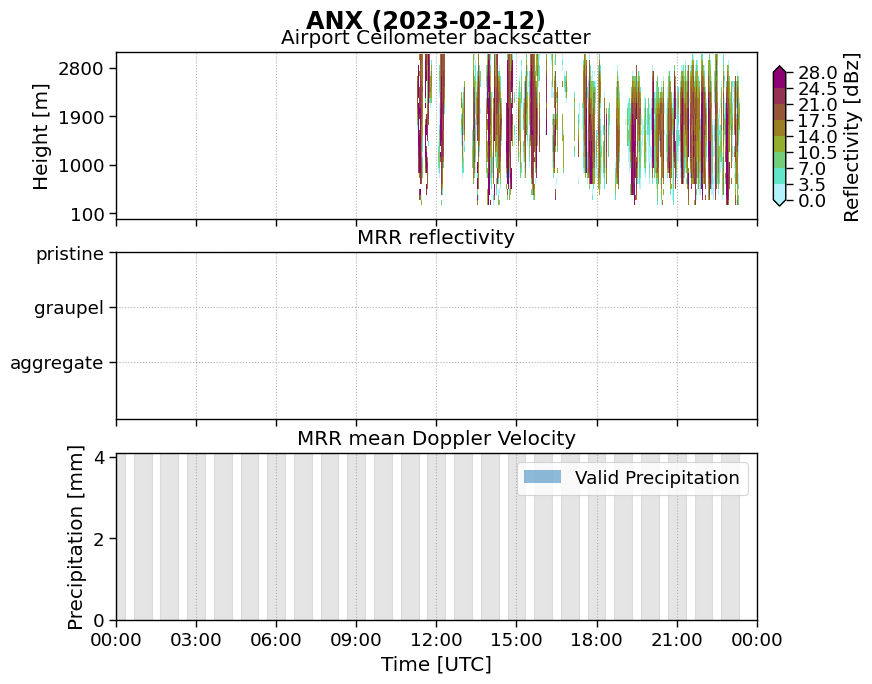

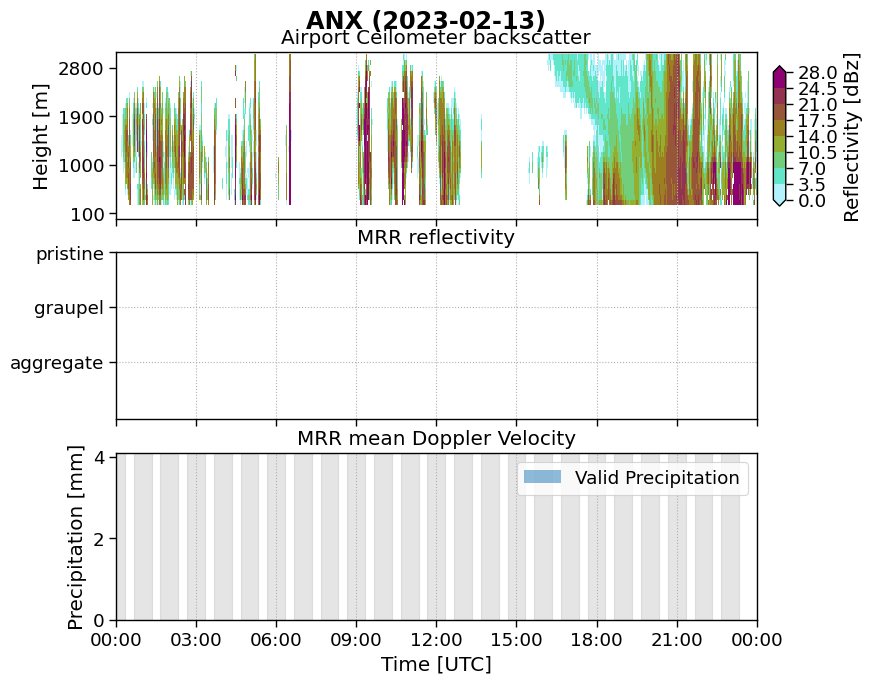

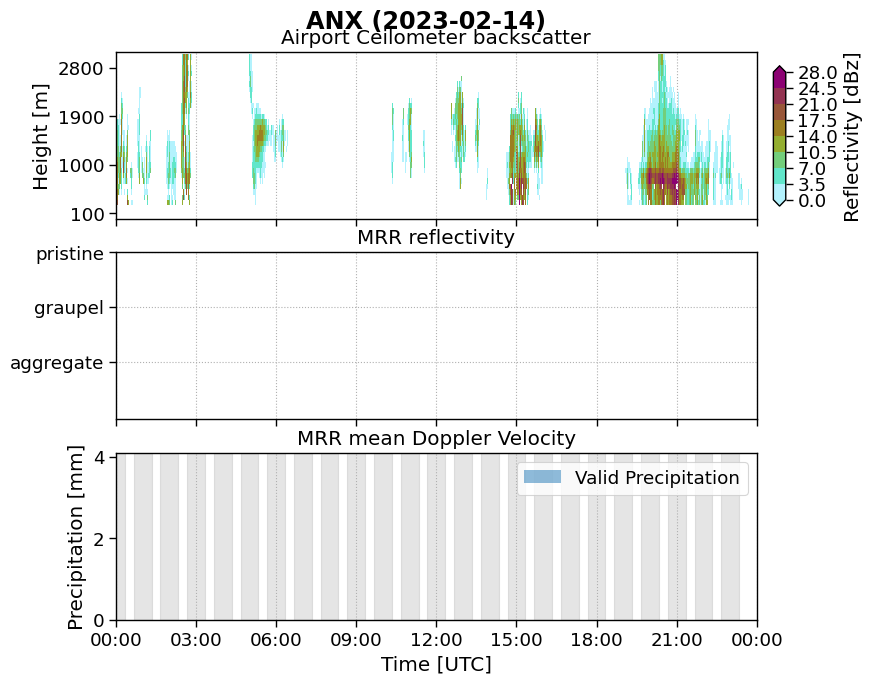

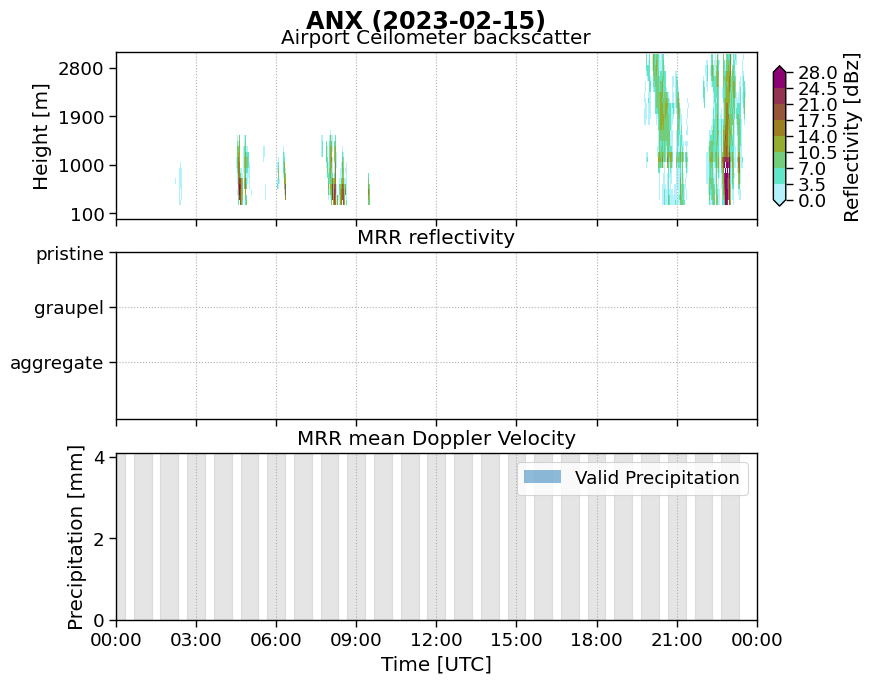

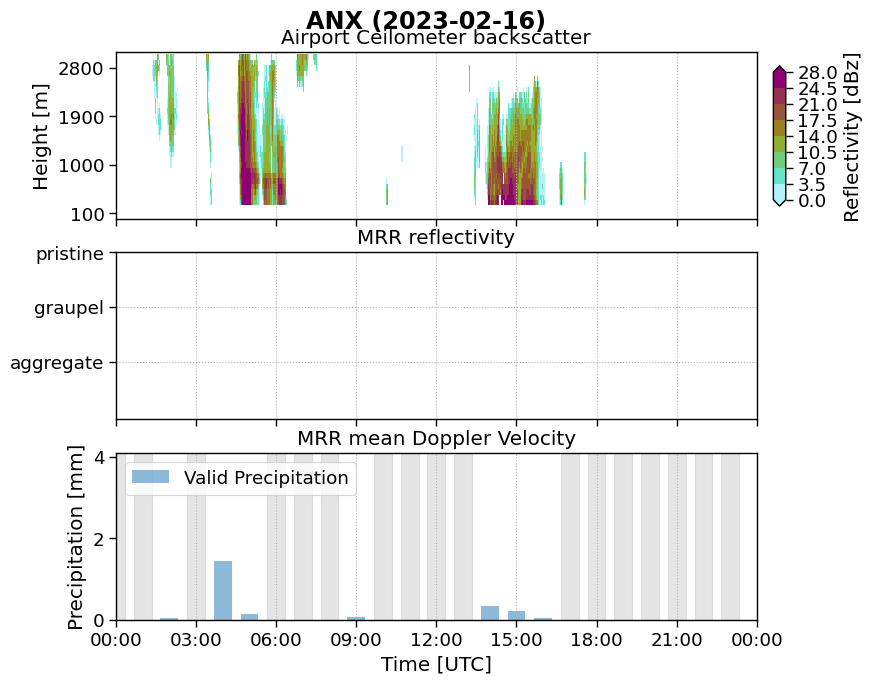

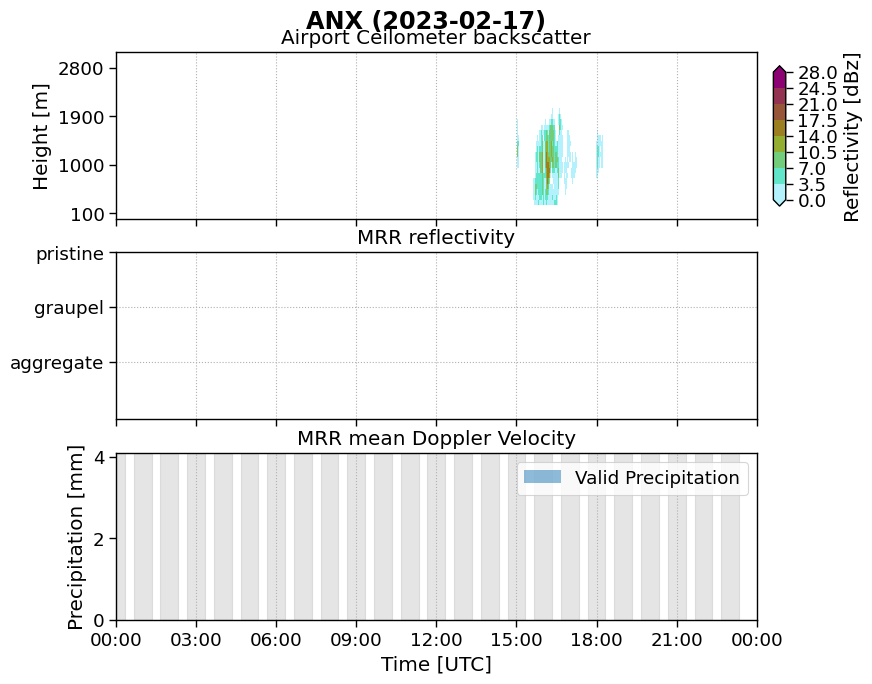

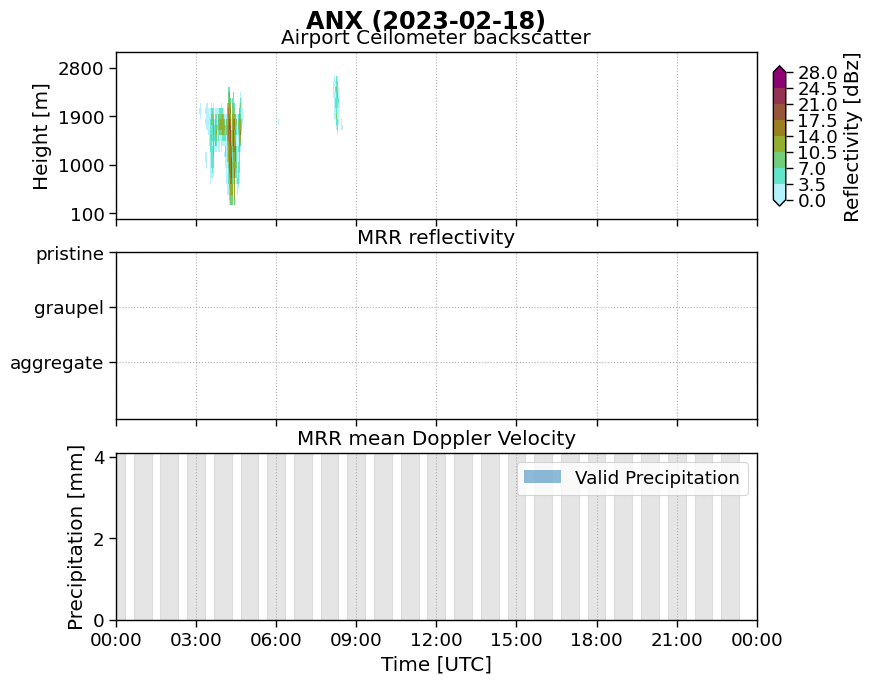

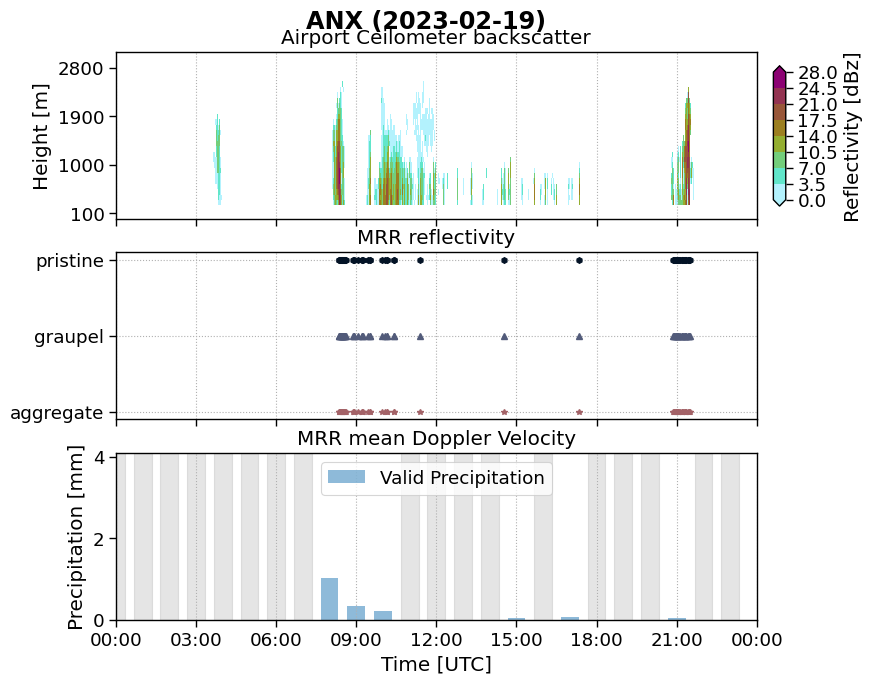

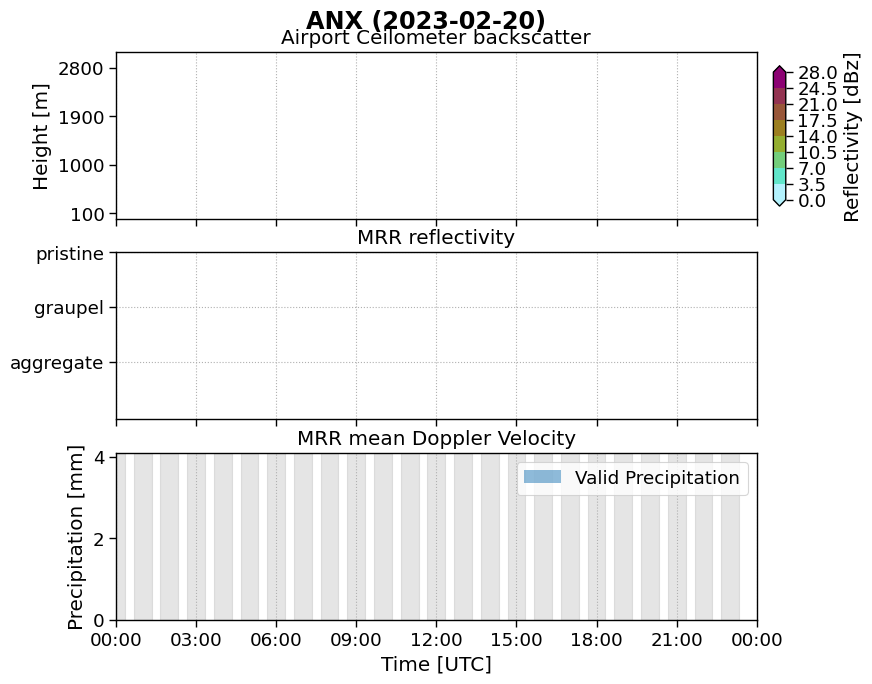

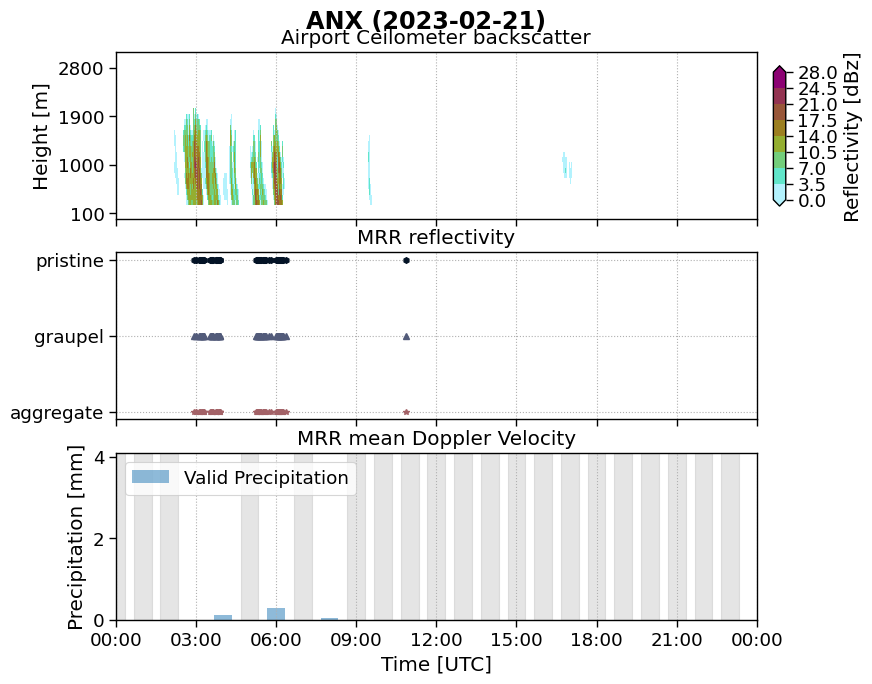

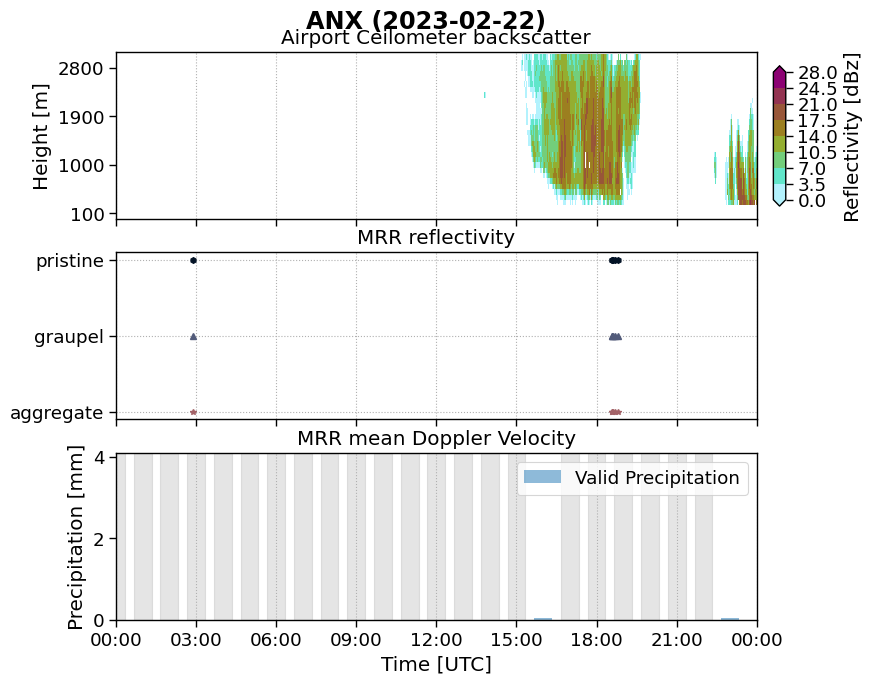

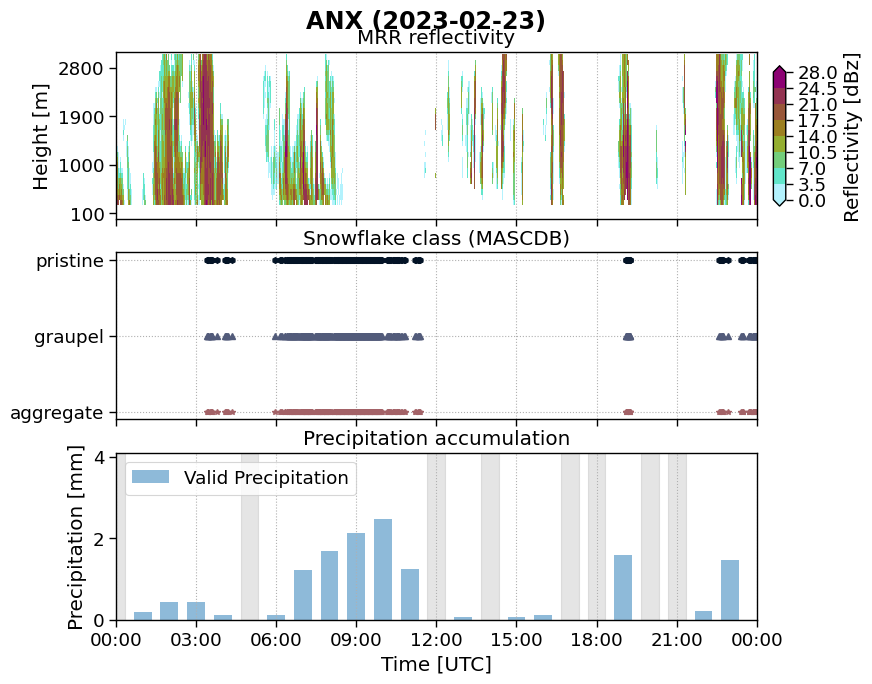

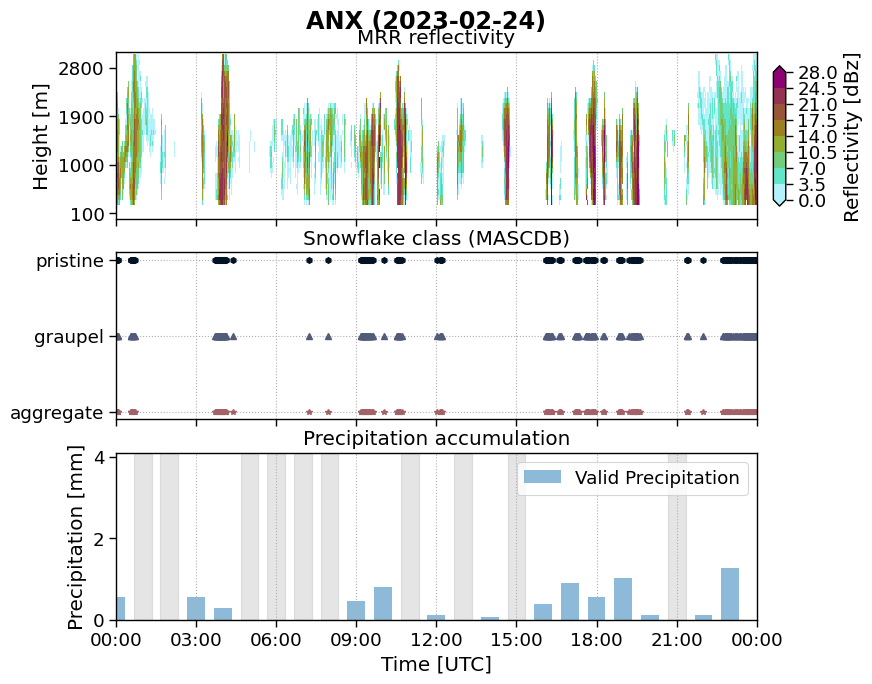

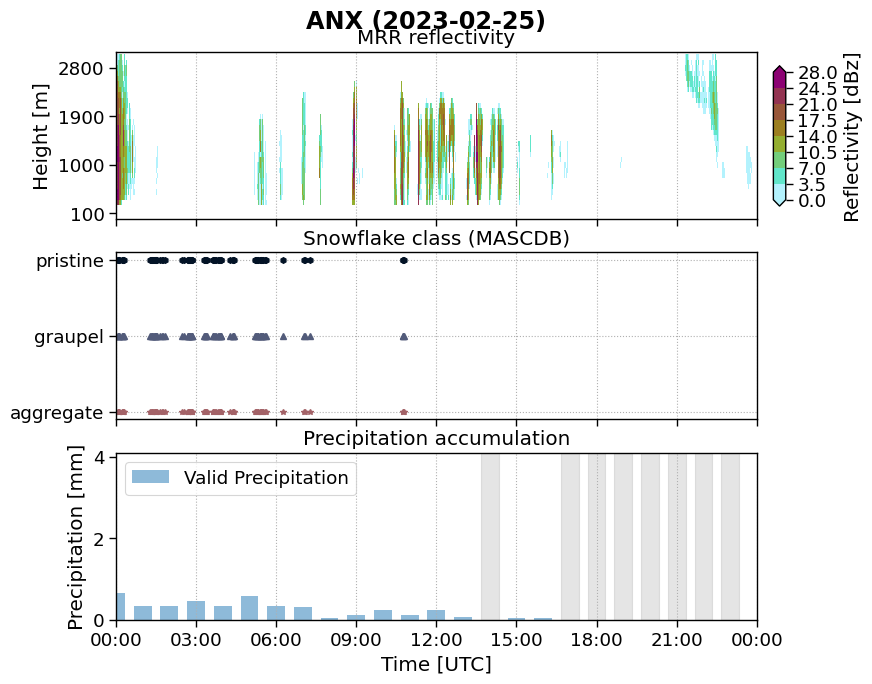

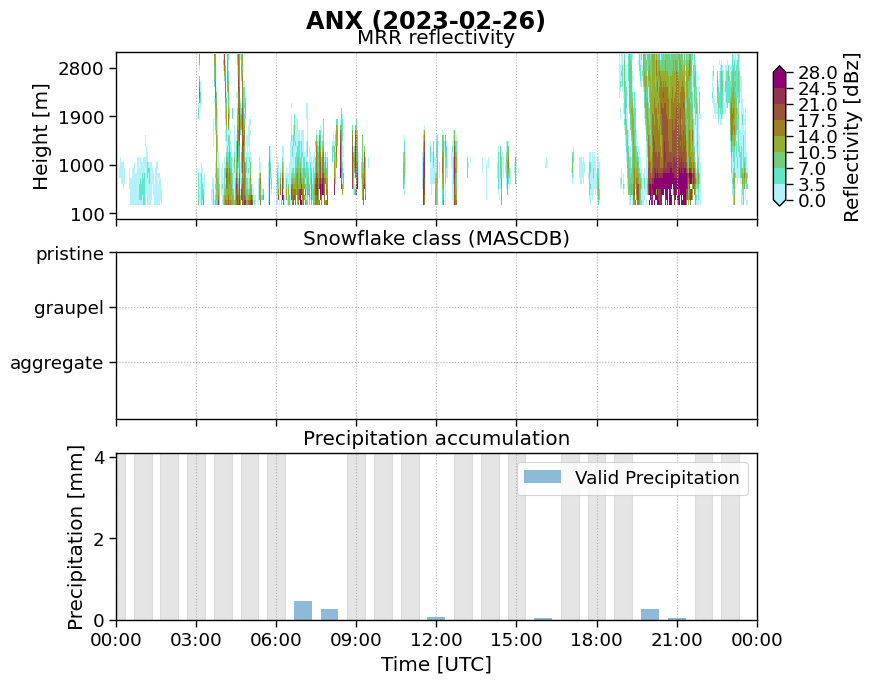

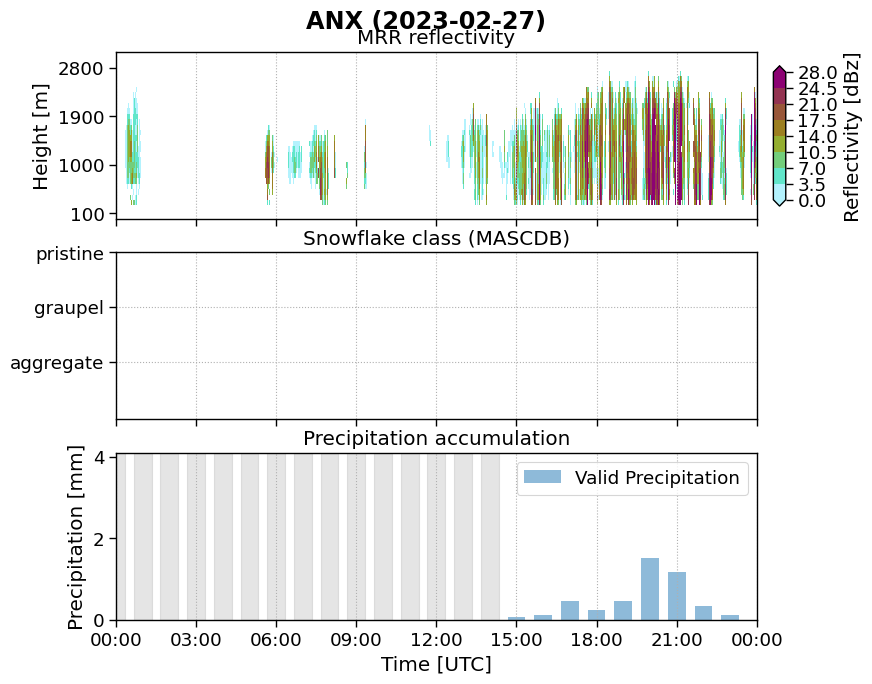

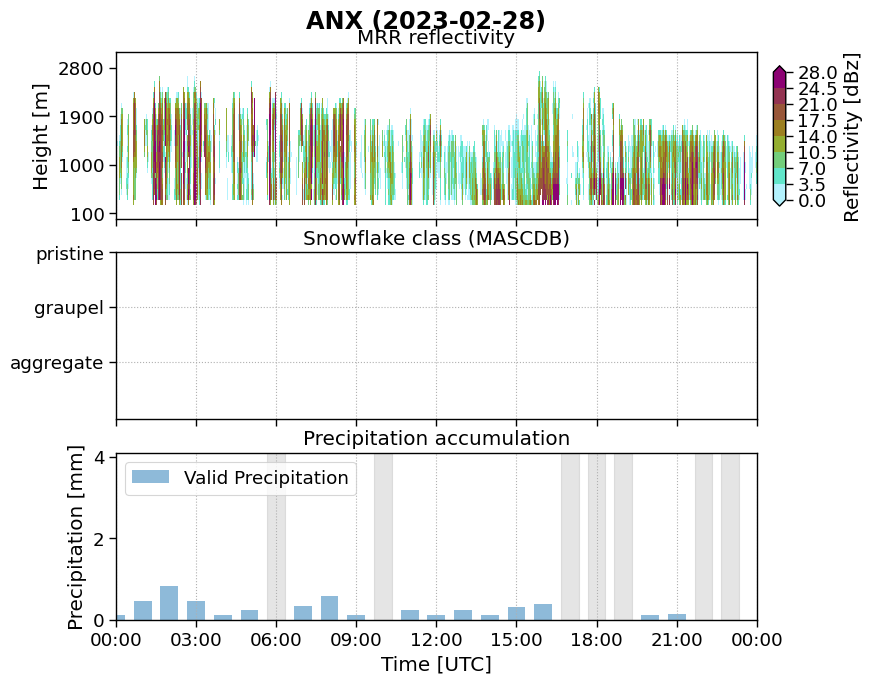

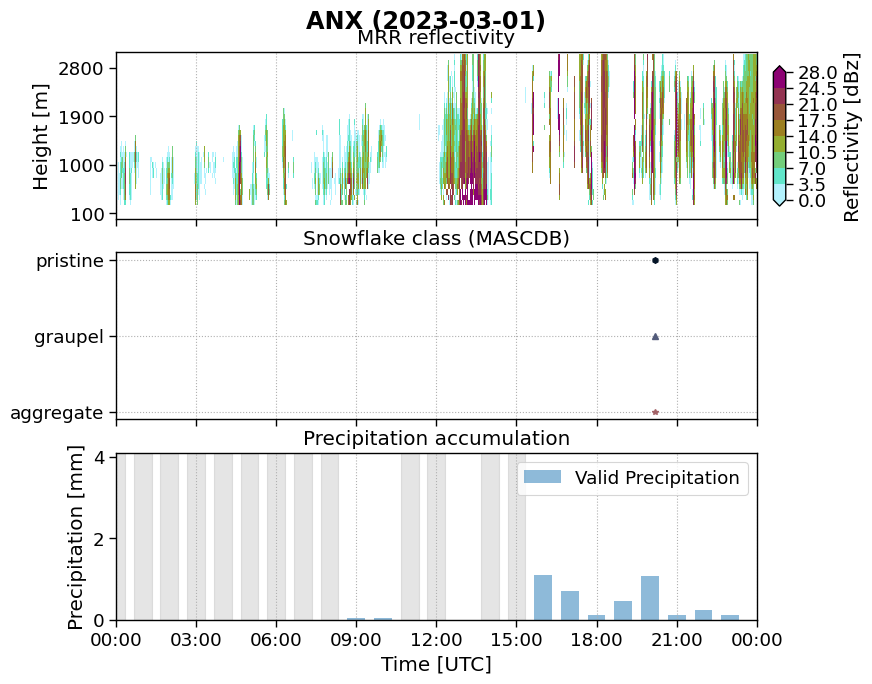

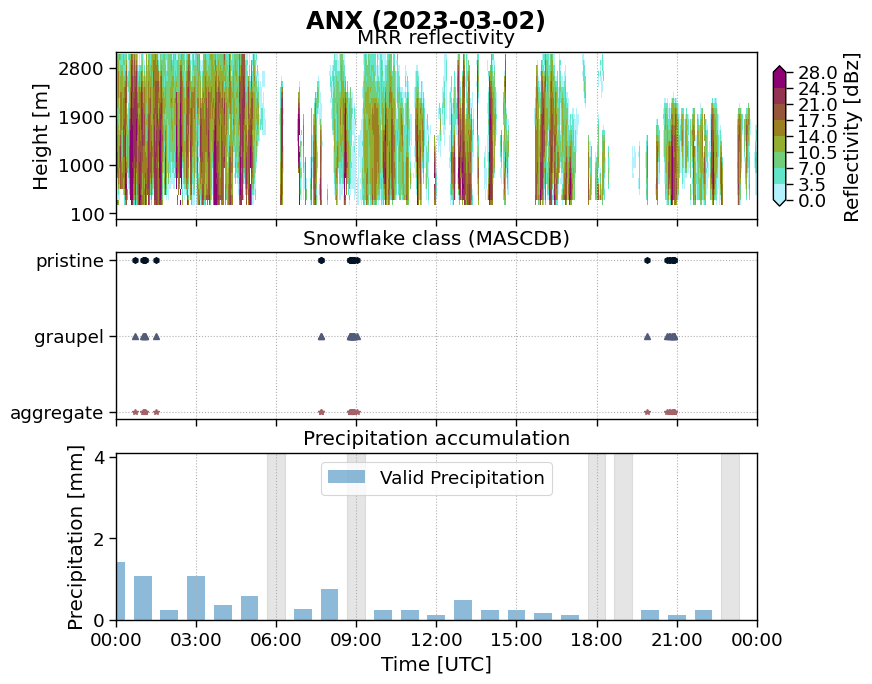

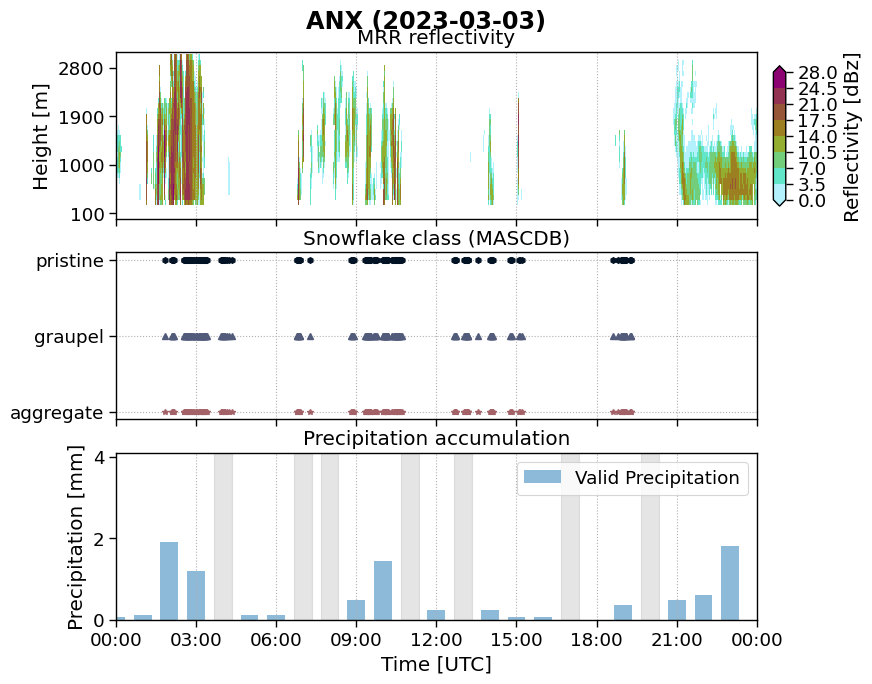

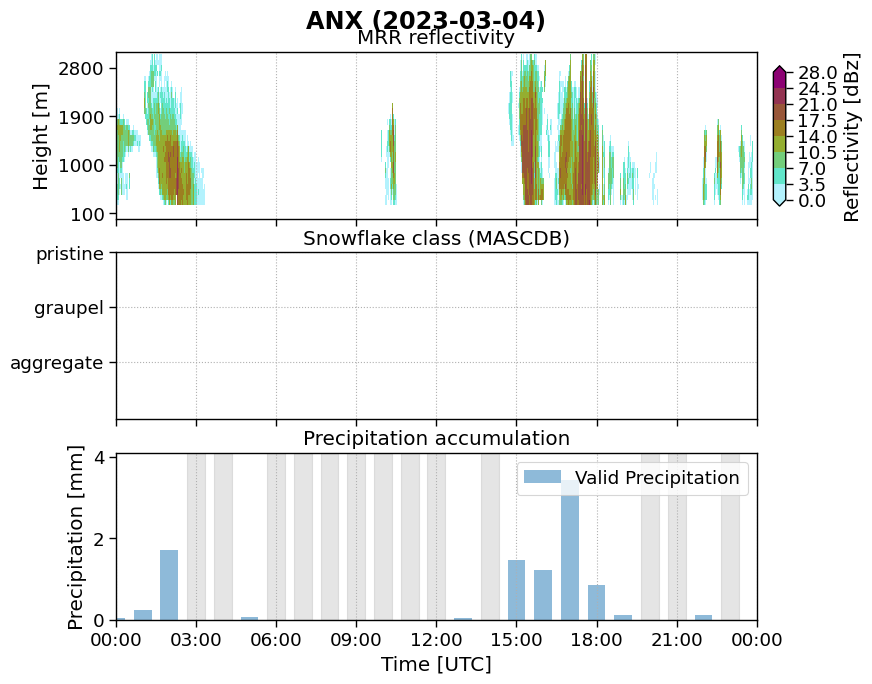

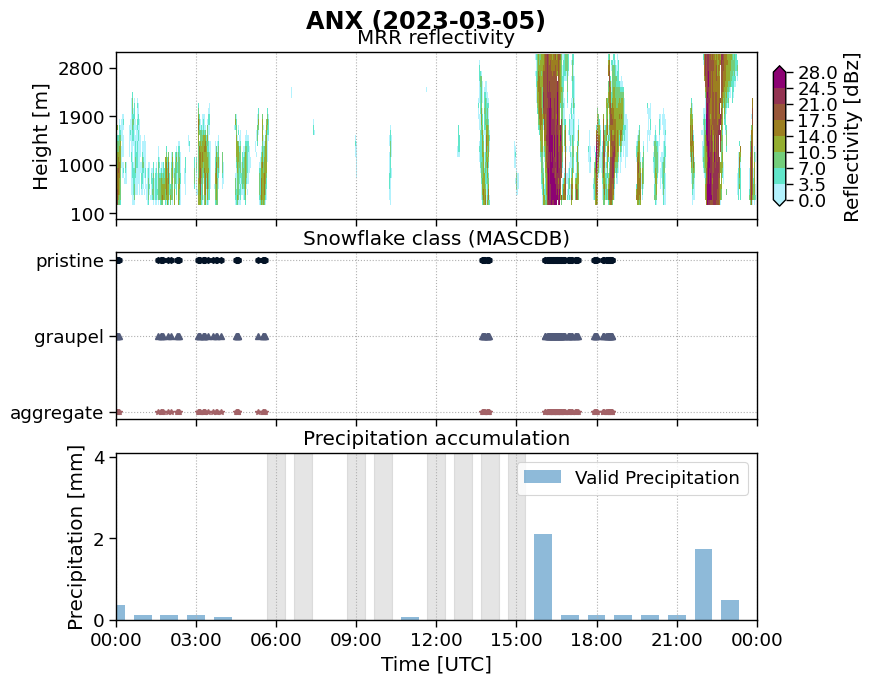

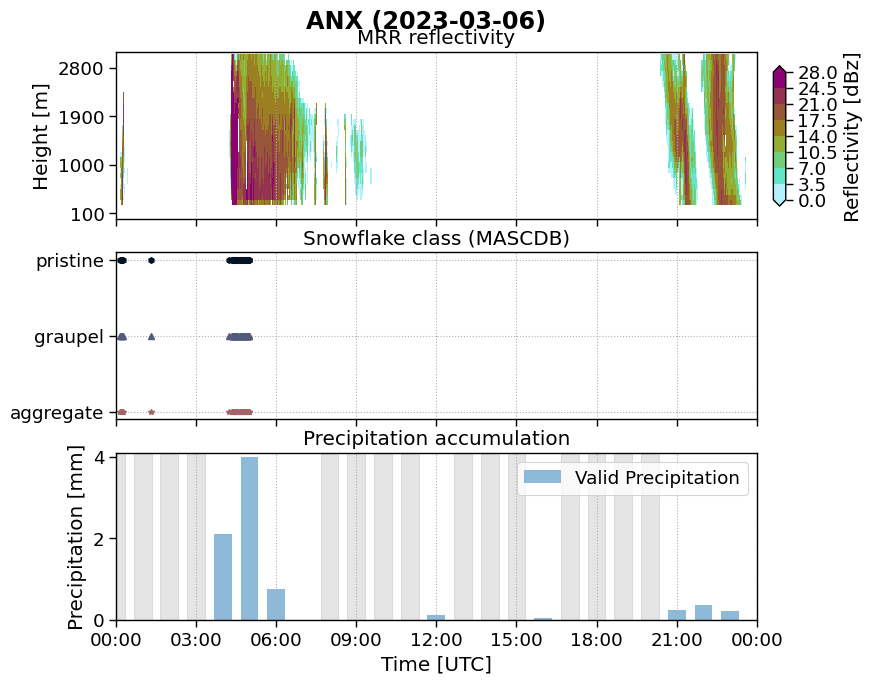

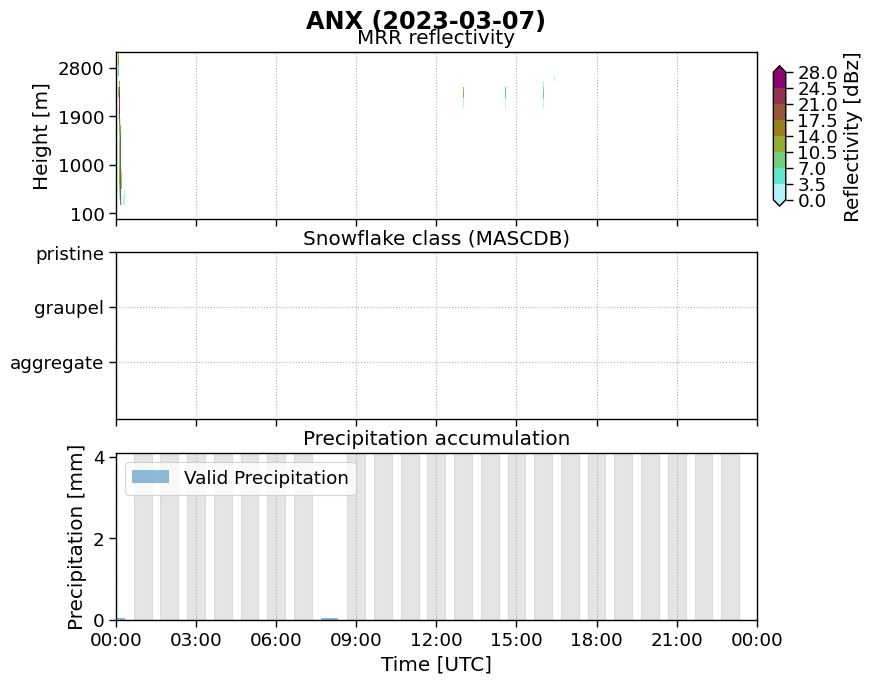

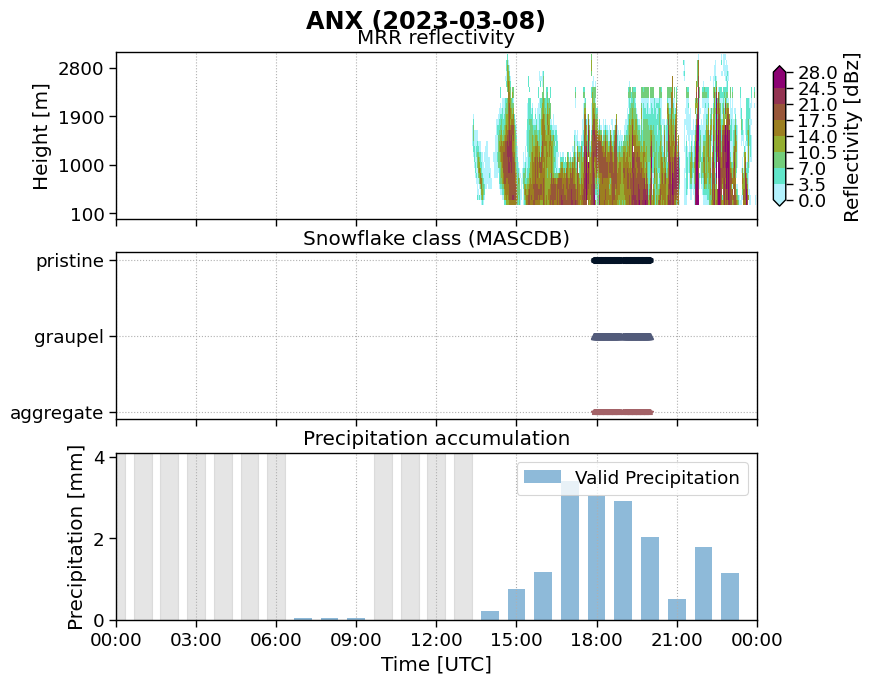

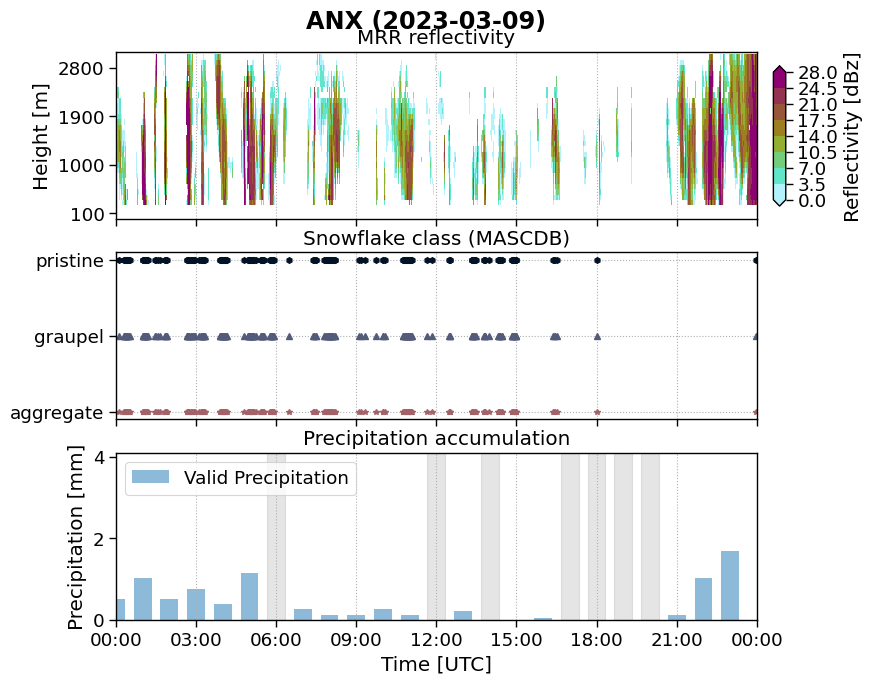

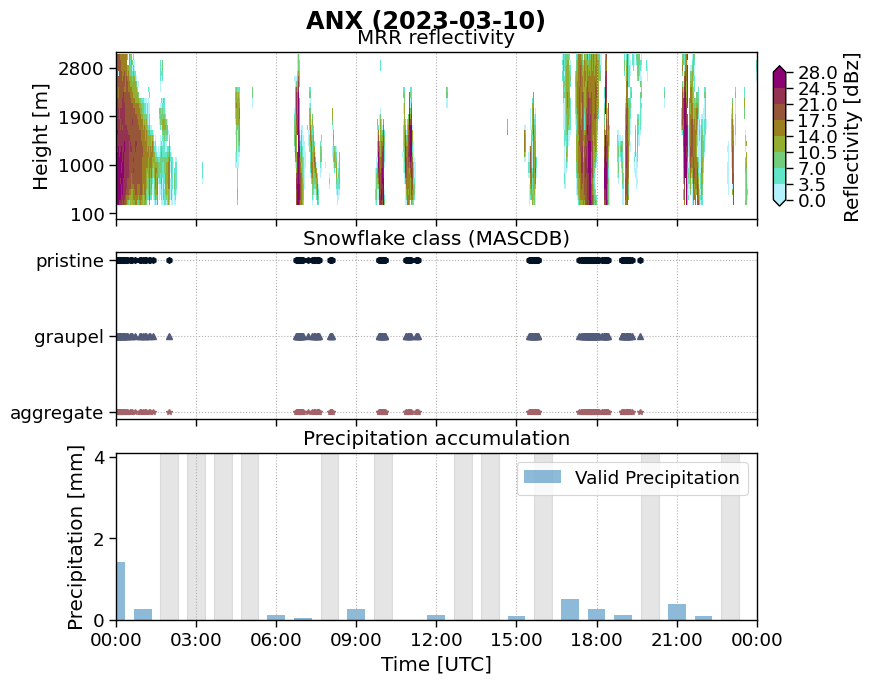

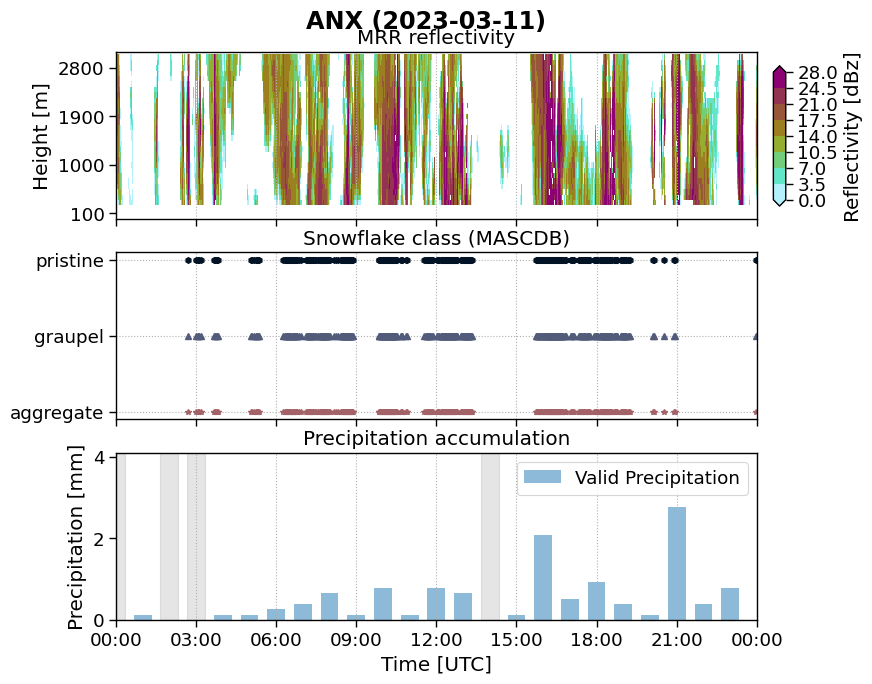

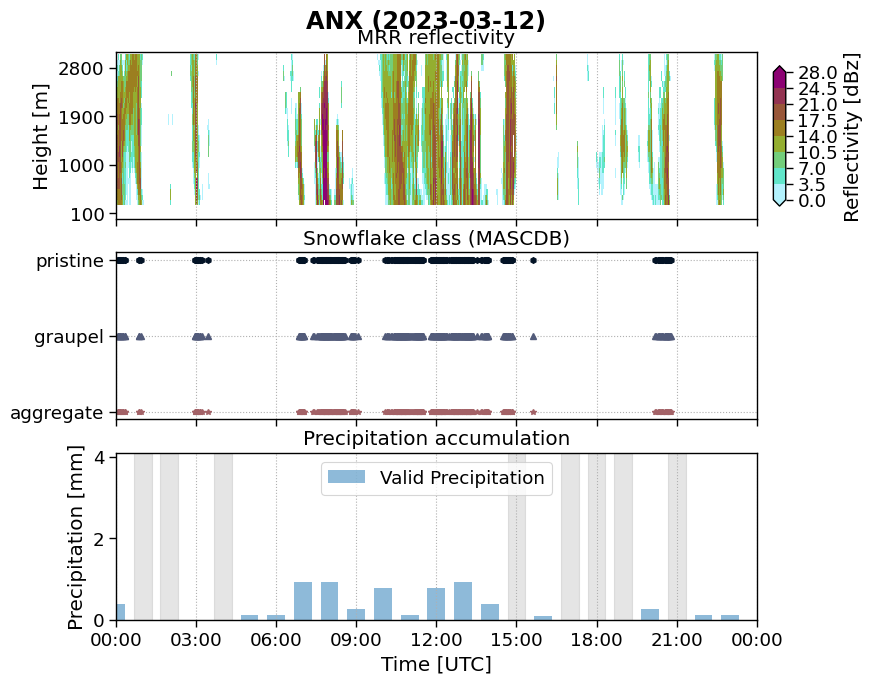

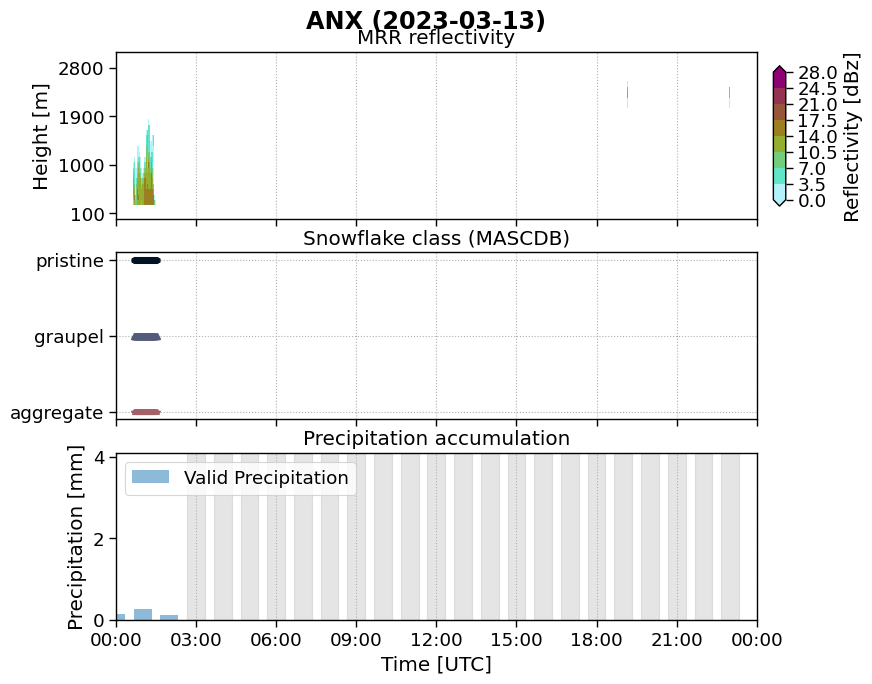

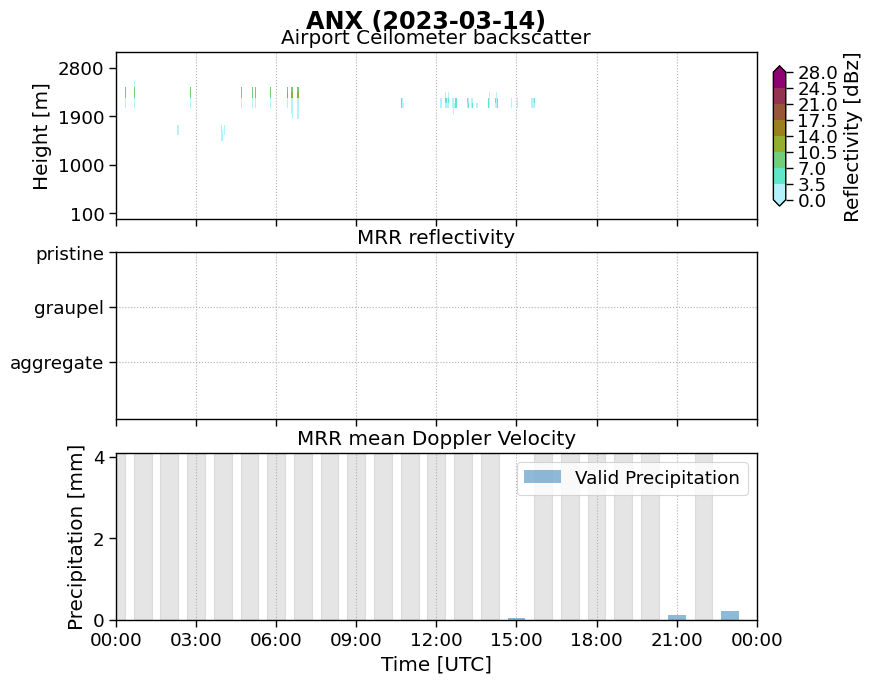

In [ ]:
for day, ds_day in ds_23.groupby("time.date"):
    day_start = pd.Timestamp(f"{day} 00:00:00")
    day_end = day_start + pd.Timedelta(hours=23, minutes=59)
    _xmax = day_start + pd.Timedelta(hours=24)

    fct.plt_Ze_W_p_T_U(ds_day, day_start, _xmax, site)

    # save image to png
    # plt.savefig(FIG_DIR + f'Ze_snowflake_class_precip_{site}_{day}.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

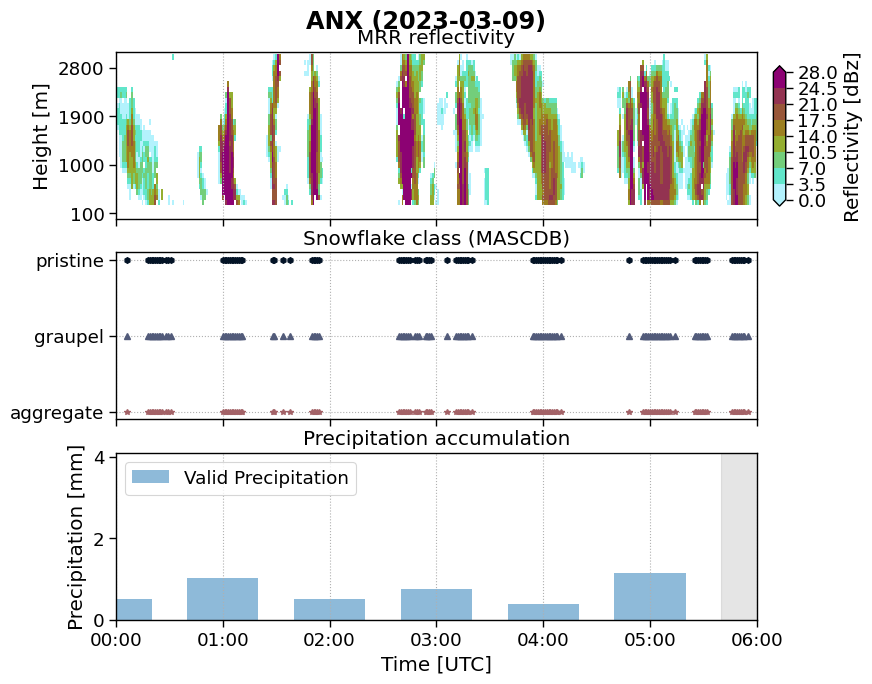

In [ ]:
site='ANX'
date = '20230309'
day_start = pd.Timestamp(f"{date} 00:00:00")
day_end = day_start + pd.Timedelta(hours=23, minutes=59)
_xmax = day_start + pd.Timedelta(hours=6)


fct.plt_Ze_W_p_T_U(ds_23.sel(time=date), day_start, _xmax, site)
# save image to png
# plt.savefig(FIG_DIR + f'Ze_snowflake_class_precip_{site}_20230309.png', format='png', bbox_inches='tight', dpi=300, )#transparent=True,)

### Sum the retrieved precipitation amount between the changes in precipitation at the Geonor


In [ ]:
df_sum = ds_23[['precipitation', 'Matrosov_aggregate', 'Bracci_aggregate', 'Nakai_aggregate', 'Nakai_graupel', 'Pu_graupel', 'Ze_linear']].sel(time=slice('2023-02-15', '2023-03-14')).to_dataframe()
df_sum.rename(columns={'Ze_linear': 'Ze_linear_sum'}, inplace=True)

df_mean = ds_23[['air_temperature', 'wind_direction', 'wind_speed', 'Ze_400m', 'Ze_linear', 'W_400m']].sel(time=slice('2023-02-15', '2023-03-14')).to_dataframe()
df_mean.rename(columns={'Ze_linear': 'Ze_linear_mean'}, inplace=True)
df_mean['W_400m'] = df_mean['W_400m']*(-1)

### Load the snowflake class names to find the dominant class within dTime change at the Geonor


In [ ]:
sf_class = xr.open_dataset(os.path.join(INPUT_DATA_DIR, 'MASC_DB', 'Norway-2023_MASCDB_aggregate_graupel_pristine.nc'), decode_times=True)[['snowflake_class_name', 'fallspeed']].to_dataframe()

In [ ]:
# Limit the fallspeed from MRR and MASC to "realistic values"
df_mean['W_400m'][df_mean['W_400m'] > 7.] = np.nan
df_mean['W_400m'][df_mean['W_400m'] <= 0.2] = np.nan

sf_class['fallspeed'][sf_class['fallspeed'] > 7.] = np.nan
sf_class['fallspeed'][sf_class['fallspeed'] <= 0.2] = np.nan

In [ ]:
notna_idx = df_sum['precipitation'].dropna().index
notna_idx = notna_idx.append(pd.Index([df_sum.index[-1]]))

sums = []
means = []
sclass = []
fs = []
# First segment: from start → first non-NaN
sums.append(df_sum.loc[:notna_idx[0]].sum(numeric_only=True, min_count=1))
means.append(df_mean.loc[:notna_idx[0]].mean(numeric_only=True, skipna=True))
if len(sf_class.loc[:notna_idx[0]]) != 0:
    sclass = fct.test_and_return_dominant_sf_class(sf_class['snowflake_class_name'].loc[:notna_idx[0]], sclass)
    fs.append((sf_class['fallspeed'].loc[:notna_idx[0]]).mean(numeric_only=True, skipna=True))
else:
    sclass.append(np.nan)
    fs.append(np.nan)

for i in range(len(notna_idx)-1):
    seg = df_sum.loc[notna_idx[i] + pd.Timedelta(seconds=1) : notna_idx[i+1]]
    seg_m = df_mean.loc[notna_idx[i] + pd.Timedelta(seconds=1) : notna_idx[i+1]]
    seg_sf = sf_class.loc[notna_idx[i] + pd.Timedelta(seconds=1) : notna_idx[i+1]]

    all_T_s = seg_m['air_temperature'].dropna()
    if (len(all_T_s) != 0) & (sum(all_T_s >2.) >=1):
        seg[:] = np.nan
        seg_m[:] = np.nan
        seg_sf[:] = np.nan

    sums.append(seg.sum(numeric_only=True, min_count=1))
    means.append(seg_m.mean(numeric_only=True, skipna=True))
    

    if len(seg_sf) != 0:
        sclass = fct.test_and_return_dominant_sf_class(seg_sf['snowflake_class_name'], sclass)
        fs.append(seg_sf['fallspeed'].mean(numeric_only=True, skipna=True))
    else:
        sclass.append(np.nan)
        fs.append(np.nan)


    # 

# Create one DataFrame with all necessary values
df_corrected = pd.concat([pd.DataFrame(sums).set_index(notna_idx), 
                          pd.DataFrame(means).set_index(notna_idx), 
                          pd.DataFrame({"snowflake_class_name":sclass}).set_index(notna_idx), 
                          pd.DataFrame({"fallspeed":fs}).set_index(notna_idx)], axis=1)
df_corrected.rename(columns={"precipitation":"Geonor",}, inplace=True)


# Compute Z from linear sums
# Compute safely: return NaN for invalid values
df_corrected['Z_from_linear_sum'] = df_corrected['Ze_linear_sum'].apply(lambda y: 10 * np.log10(y) if y > 0 else np.nan)
df_corrected['Z_from_linear_mean'] = df_corrected['Ze_linear_mean'].apply(lambda y: 10 * np.log10(y) if y > 0 else np.nan)
## Convert snowfall increments to rate (mm/h)
# Calculate time difference in hours
df_corrected["delta_h"] = df_corrected.index.to_series().diff().dt.total_seconds() / 3600

# Convert to mm/h rate
df_corrected["rate_mm_h"] = df_corrected["Geonor"] / df_corrected["delta_h"]

# # Save to file
# for day, df_day in df_corrected.groupby(pd.Grouper(freq='D')):
#     day = day.strftime('%Y%m%d')
#     filename = f"Z_S_2Tm_WD_WS_class_varying_time_{site}_{day}.nc"
#     # print(len(df_day))
#     if len(df_day) != 0:
#         print(f"...writing file: {filename}")
#         df_day.to_xarray().to_netcdf(os.path.join(nc_dir, filename))

In [ ]:
df_only_class = dict()
df_only_class['aggregate'] = df_corrected[df_corrected['snowflake_class_name'] == 'aggregate']
df_only_class['graupel'] = df_corrected[df_corrected['snowflake_class_name'] == 'graupel']
df_only_class['mixed'] = df_corrected[df_corrected['snowflake_class_name'] == 'mixed']
df_only_class['pristine'] = df_corrected[df_corrected['snowflake_class_name'] == 'pristine']

In [ ]:
seconds_to_subtract = 400 / df_corrected['fallspeed']
# time_delta = timedelta(seconds=seconds_to_subtract.iloc[0])
# new_datetime = df_corrected.index[0] - time_delta
# Convert seconds into timedeltas
timedeltas = pd.to_timedelta(seconds_to_subtract, unit='sec')
# Convert to minutes as a float, round, and then convert back to timedelta64[m]
rounded_td = (timedeltas / np.timedelta64(1, 'm')).round().astype('timedelta64[m]')

# Subtract from index
df_corrected['shifted_time_end'] = df_corrected.index - rounded_td
# nearest_idx = df_sum.index.get_indexer([df_corrected['shifted_time'][i]], method='nearest',tolerance=pd.Timedelta('1min'))[0]

In [ ]:
# Define start and end of window to exclude/include
start = pd.Timestamp("2023-03-08 23:30")
end = pd.Timestamp("2023-03-09 06:00")

# # mask for rows outside the range
# mask = (df_corrected.index < start) | (df_corrected.index > end)
# # select all rows not in that window
# df_exclude = df_corrected.loc[mask]

# mask for inside the range
mask = (df_corrected.index >= start) & (df_corrected.index <= end)
df_09 = df_corrected.loc[mask]



In [ ]:
# delta_minutes = pd.to_timedelta(df_09['delta_h'], unit='hours')
# rounded_td_min = (delta_minutes / np.timedelta64(1, 'm')).round().astype('timedelta64[m]')
# df_09['shifted_time_start'] = df_09['shifted_time_end'] - rounded_td_min
# # df_09['shifted_time_start'] = df_09.index[:-1] - rounded_td[1:]

In [ ]:
mask = (df_sum.index >= start) & (df_sum.index <= end)
df_sum_09 = df_sum.loc[mask]
df_mean_09 = df_mean.loc[mask]

In [ ]:
df_sum

,precipitation,Matrosov_aggregate,Bracci_aggregate,Nakai_aggregate,Nakai_graupel,Pu_graupel,Ze_linear_sum
time,,,,,,,
2023-02-15 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-15 00:01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-15 00:02:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-15 00:03:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-15 00:04:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2023-03-14 23:55:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-14 23:56:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-14 23:57:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_sum_09 = df_sum[['Matrosov_aggregate', 'Bracci_aggregate', 'Nakai_aggregate', 'Nakai_graupel', 'Pu_graupel', 'Ze_linear_sum']]

In [ ]:
df_mean_09 = df_mean[['Ze_400m', 'Ze_linear_mean', 'W_400m']]

In [ ]:

sums = []
means= []
for i in range(len(df_corrected)-1):
    seg = df_sum_09.loc[df_corrected['shifted_time_end'][i] + pd.Timedelta(seconds=1) : df_corrected['shifted_time_end'][i+1]]
    seg_m = df_mean_09.loc[df_corrected['shifted_time_end'][i] + pd.Timedelta(seconds=1) : df_corrected['shifted_time_end'][i+1]]
    seconds_to_subtract = 400 / df_corrected['fallspeed'][i]
    # time_delta = timedelta(seconds=seconds_to_subtract.iloc[0])
    # new_datetime = df_corrected.index[0] - time_delta
    # Convert seconds into timedeltas
    timedeltas = pd.to_timedelta(seconds_to_subtract, unit='sec')
  
    # print(df_corrected.index[i], seg)
    sums.append(seg.sum(numeric_only=True, min_count=1))
    means.append(seg_m.mean(numeric_only=True, skipna=True))


In [ ]:
df_corrected_t_offset = pd.concat([df_corrected[['shifted_time_end', 'Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'snowflake_class_name', 'fallspeed', 'delta_h', 'rate_mm_h']],
                                   pd.DataFrame(sums).set_index(df_corrected.index[1:]), 
                                   pd.DataFrame(means).set_index(df_corrected.index[1:]), ], axis=1)# df_corrected['shifted_time_end'][1:].reset_index(drop=True)], axis=1)

df_corrected_t_offset['Matrosov_aggregate'].dropna().head(6)

2023-02-19 08:33:00      0.034742
2023-02-19 08:40:00      0.018540
2023-02-19 08:48:00    105.037270
2023-02-19 09:33:00      0.006162
2023-02-19 09:47:00    105.030736
2023-02-19 10:25:00      0.273494
Name: Matrosov_aggregate, dtype: float64

In [ ]:
# Ze_dbz = df_corrected_t_offset['Ze_400m']
# Ze_lin = 10 ** (Ze_dbz /10)
Ze_lin_toff = df_corrected_t_offset['Ze_linear_sum']
S_toff = (Ze_lin_toff / 56) ** (1/1.2)

In [ ]:
mas_toff = S_toff #/ df_corrected_t_offset['delta_h']

In [ ]:
Ze_lin = df_corrected['Ze_linear_sum']
S = (Ze_lin / 56) ** (1/1.2)
mas = S

Text(0.5, 0, 'Geonor [mm h$^{-1}$]')

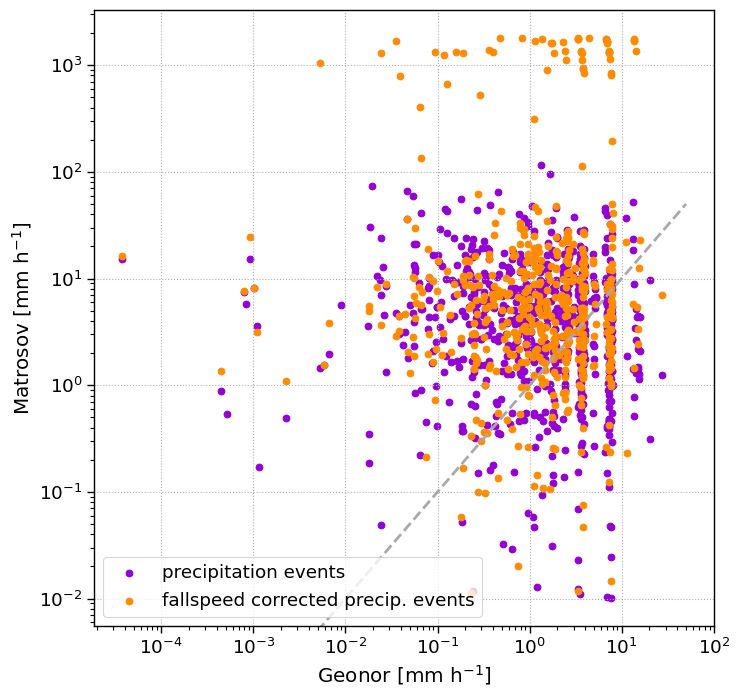

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8, ), sharex=True, sharey=True)

ax.scatter(df_corrected['rate_mm_h'], mas, color='darkviolet', label='precipitation events')
ax.scatter(df_corrected_t_offset['rate_mm_h'], mas_toff, color='darkorange', label='fallspeed corrected precip. events')

ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()

x = np.linspace(0, 50, 100)
y = x
ax.plot(x, y, linestyle='--', color='darkgrey')

ax.grid(True, ls=':')

ax.set_ylabel('Matrosov [mm h$^{-1}]$')
ax.set_xlabel('Geonor [mm h$^{-1}$]')

Text(0, 0.5, 'Ze time offset [mm$^{6}$ m$^{-3}$]')

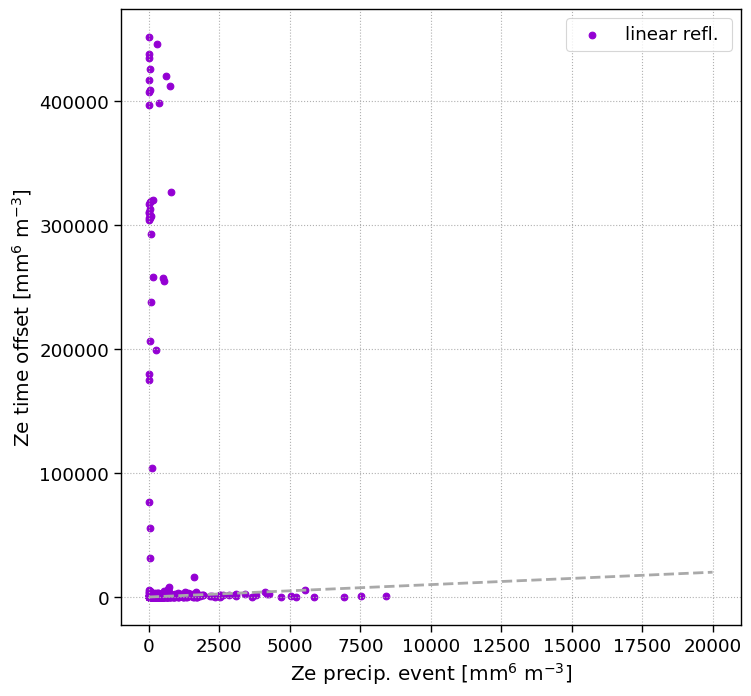

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8, ), sharex=True, sharey=True)

ax.scatter(df_corrected['Ze_linear_sum'], df_corrected_t_offset['Ze_linear_sum'], color='darkviolet', label='linear refl. ')
# ax.scatter(df_corrected_t_offset['rate_mm_h'], df_corrected_t_offset['Matrosov_aggregate'], color='darkorange', label='fallspeed corrected precip. events')

# ax.set_xscale('log')
# ax.set_yscale('log')
ax.legend()

x = np.linspace(0, 20000, 100)
y = x
ax.plot(x, y, linestyle='--', color='darkgrey')

ax.grid(True, ls=':')

ax.set_xlabel('Ze precip. event [mm$^{6}$ m$^{-3}]$')
ax.set_ylabel('Ze time offset [mm$^{6}$ m$^{-3}$]')

# ax.set_xlim([0,2000])
# ax.set_ylim([0,2000])

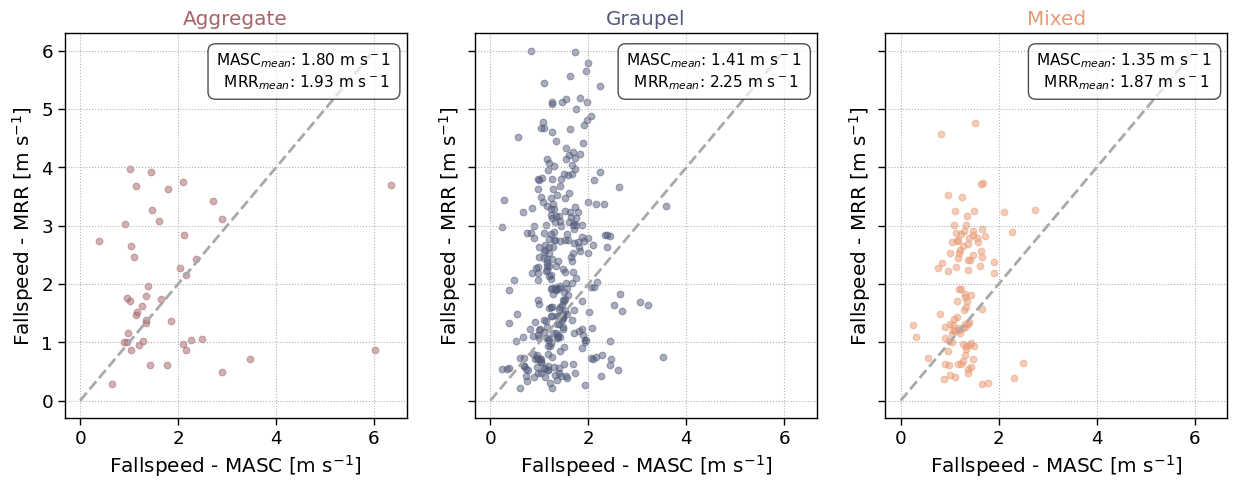

In [ ]:
custom_colors = {key: fct.custom_colors[key] for key in ['aggregate', 'graupel', 'mixed']}


fig, axsm = plt.subplots(1, 3, figsize=(15, 5, ), sharex=True, sharey=True)
axs = axsm.flatten()

for ax, (class_name, color) in zip(axs, custom_colors.items()):
    ax.scatter(df_only_class[class_name]['fallspeed'], df_only_class[class_name]['W_400m'], color=color, alpha=0.5, edgecolor=color,)
    masc_mean = df_only_class[class_name]['fallspeed'].mean(skipna=True)
    mrr_mean = df_only_class[class_name]['W_400m'].mean(skipna=True)
    ax.text(0.7, 0.9, f"MASC$_{{mean}}$: {masc_mean:.2f} m s$^{-1}$ \n MRR$_{{mean}}$: {mrr_mean:.2f} m s$^{-1}$", transform=ax.transAxes, fontsize=11, ha='center', va='center', bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='k', lw=1, alpha=0.7))
    
    ax.set(xlabel = "Fallspeed - MASC [m s$^{-1}$]", ylabel="Fallspeed - MRR [m s$^{-1}$]")
    ax.grid(True, ls=':')
    ax.set_title(f"{class_name}".title(), color=color)
    
    x = np.linspace(0, 6, 100)
    y = x

    ax.plot(x, y, linestyle='--', color='darkgrey')

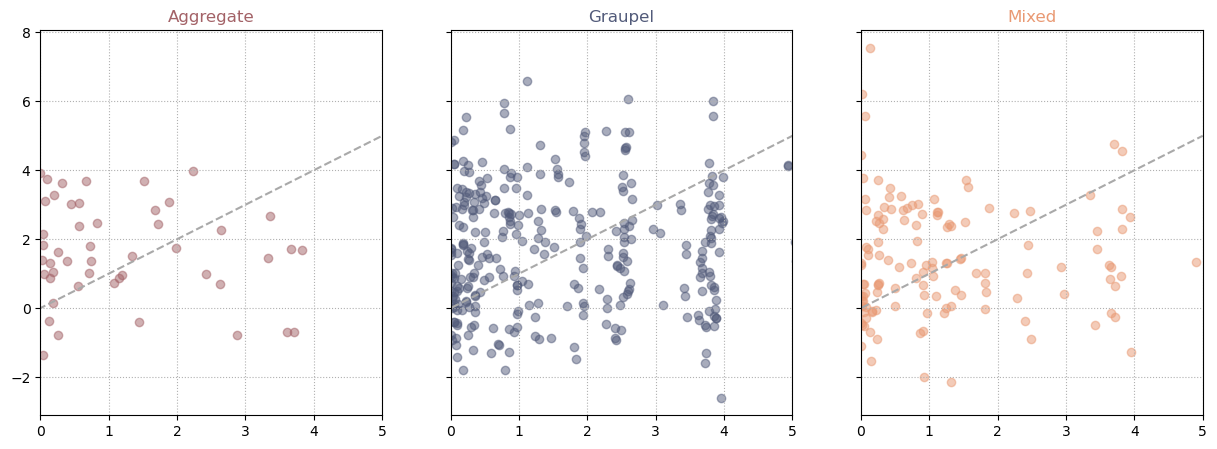

In [ ]:
fig, axsm = plt.subplots(1, 3, figsize=(15, 5, ), sharex=True, sharey=True)
axs = axsm.flatten()

for ax, (class_name, color) in zip(axs, custom_colors.items()):
    ax.scatter(df_only_class[class_name]['rate_mm_h'], df_only_class[class_name]['W_400m'], color=color, alpha=0.5, edgecolor=color,)
    
    # ax.set(xlabel = "Fallspeed - MASC [m s$^{-1}$]", ylabel="Fallspeed - MRR [m s$^{-1}$]")
    ax.grid(True, ls=':')
    ax.set_title(f"{class_name}".title(), color=color)
    # ax.xaxis('log')
    
    x = np.linspace(-2, 5, 100)
    y = x
    
    ax.set_xlim([0,5])
    ax.plot(x, y, linestyle='--', color='darkgrey')

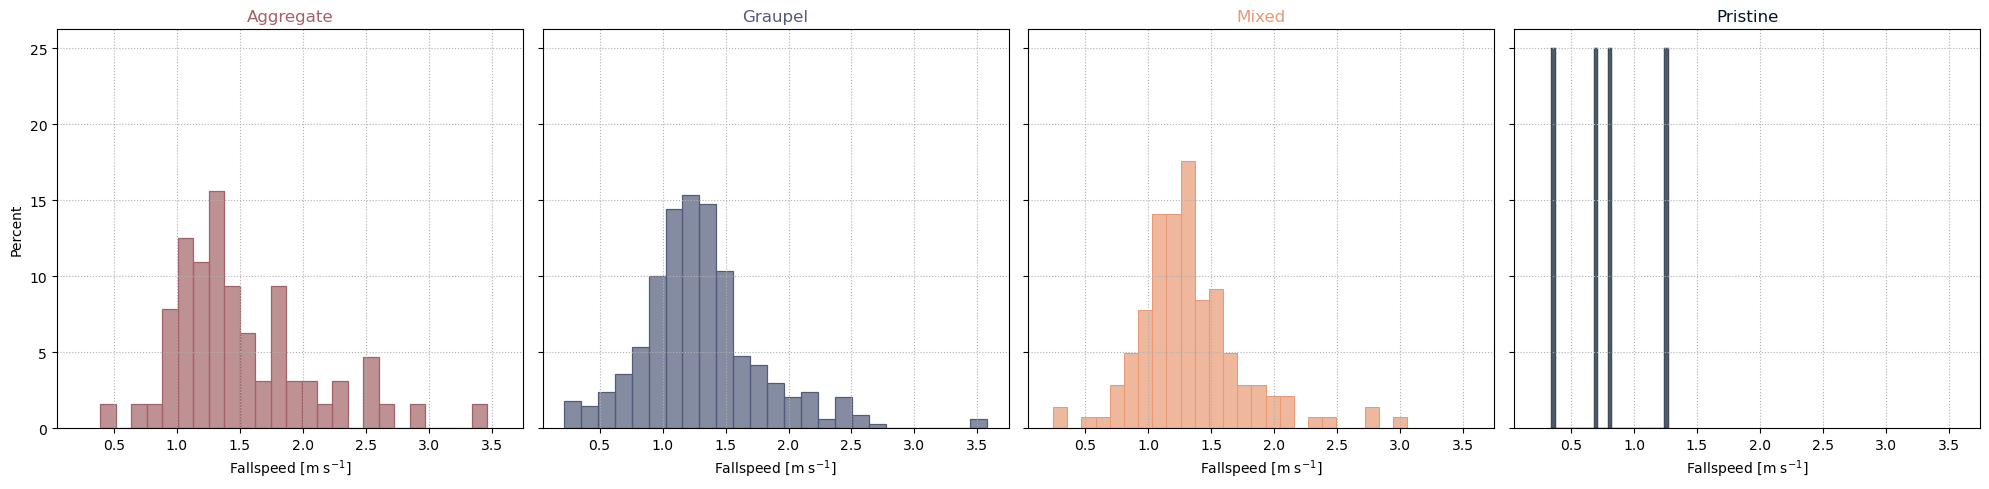

In [ ]:


fig, axsm = plt.subplots(1, 4, figsize=(20, 5, ), sharex=True, sharey=True)
axs = axsm.flatten()

for ax, (class_name, color) in zip(axs, fct.custom_colors.items()):
    sns.histplot(df_only_class[class_name]['fallspeed'], bins=25, stat='percent', ax=ax, color=color, alpha=0.7, edgecolor=color )

    ax.set(xlabel = "Fallspeed [m s$^{-1}$]")
    ax.grid(True, ls=':')
    ax.set_title(f"{class_name}".title(), color=color)

plt.tight_layout()

# plt.savefig(os.path.join(FIG_DIR, 'fallspeed', 'aggregate_graupel_mixed_pristine_precip_event.png'), format='png', bbox_inches='tight', dpi=300, transparent=True,)

In [ ]:


hourly_idx = df_sum['precipitation'].resample('1H').sum(min_count=1).index # require at least 1 non-Nan value to compute the sum, otherwise return Nan
# notna_idx = notna_idx.append(pd.Index([df_sum.index[-1]]))

sums = []
means = []
sclass = []


for i in range(len(hourly_idx)-1):
    seg = df_sum.loc[hourly_idx[i]  : hourly_idx[i+1]-pd.Timedelta(minutes=1)]
    seg_m = df_mean.loc[hourly_idx[i]  : hourly_idx[i+1]-pd.Timedelta(minutes=1)]
    seg_sf = sf_class.loc[hourly_idx[i]  : hourly_idx[i+1]-pd.Timedelta(minutes=1)]

    all_T_h = seg_m['air_temperature'].dropna()
    if (len(all_T_h) != 0) & (sum(all_T_h >2.) >=1):
        seg[:] = np.nan
        seg_m[:] = np.nan
        seg_sf[:] = np.nan

    
    sums.append(seg.sum(numeric_only=True, min_count=1))
    means.append(seg_m.mean(numeric_only=True, skipna=True))

    if len(seg_sf) != 0:
        sclass = fct.test_and_return_dominant_sf_class(seg_sf, sclass)
    else:
        sclass.append(np.nan)

# Last segment: 
seg = df_sum.loc[hourly_idx[-1]:]
seg_m = df_mean.loc[hourly_idx[-1]:]
seg_sf = sf_class.loc[hourly_idx[-1]:]

all_T_h = seg_m['air_temperature'].dropna()
if (len(all_T_h) != 0) & (sum(all_T_h >2.) >=1):
    seg[:] = np.nan
    seg_m[:] = np.nan
    seg_sf[:] = np.nan
sums.append(seg.sum(numeric_only=True, min_count=1))
means.append(seg_m.mean(numeric_only=True, skipna=True))
if len(seg_sf) != 0:
    sclass = fct.test_and_return_dominant_sf_class(seg_sf, sclass)
else:
    sclass.append(np.nan)


# Create one DataFrame with all necessary values
df_corrected_1h = pd.concat([pd.DataFrame(sums).set_index(hourly_idx), pd.DataFrame(means).set_index(hourly_idx), pd.DataFrame({"snowflake_class_name":sclass}).set_index(hourly_idx)], axis=1)
df_corrected_1h.rename(columns={"precipitation":"Geonor",}, inplace=True)


# Compute Z from linear sums
# Compute safely: return NaN for invalid values
df_corrected_1h['Z_from_linear_sum'] = df_corrected_1h['Ze_linear_sum'].apply(lambda y: 10 * np.log10(y) if y > 0 else np.nan)
df_corrected_1h['Z_from_linear_mean'] = df_corrected_1h['Ze_linear_mean'].apply(lambda y: 10 * np.log10(y) if y > 0 else np.nan)
## Convert snowfall increments to rate (mm/h)
# Calculate time difference in hours
df_corrected_1h["delta_h"] = df_corrected_1h.index.to_series().diff().dt.total_seconds() / 3600

# Convert to mm/h rate
df_corrected_1h["rate_mm_h"] = df_corrected_1h["Geonor"] / df_corrected_1h["delta_h"]
# Set precipitation rate in hour smaller than 0.1 mm to nan
df_corrected_1h['rate_mm_h'][df_corrected_1h['rate_mm_h'] <= 0.1 ] = np.nan


# for day, df_day in df_corrected_1h.groupby(pd.Grouper(freq='D')):
#     day = day.strftime('%Y%m%d')
#     filename = f"Z_S_2Tm_WD_WS_class_1h_{site}_{day}.nc"
#     # print(len(df_day))
#     if len(df_day) != 0:
#         print(f"...writing file: {filename}")
#         df_day.to_xarray().to_netcdf(os.path.join(nc_dir, filename))


In [ ]:
# Define start and end of window to exclude/include
start = pd.Timestamp("2023-03-09 00:00")
end = pd.Timestamp("2023-03-09 06:00")

# mask for rows outside the range
mask = (df_corrected.index < start) | (df_corrected.index > end)
# select all rows not in that window
df_exclude = df_corrected.loc[mask]

# mask for inside the range
mask = (df_corrected.index >= start) & (df_corrected.index <= end)
df_only = df_corrected.loc[mask]


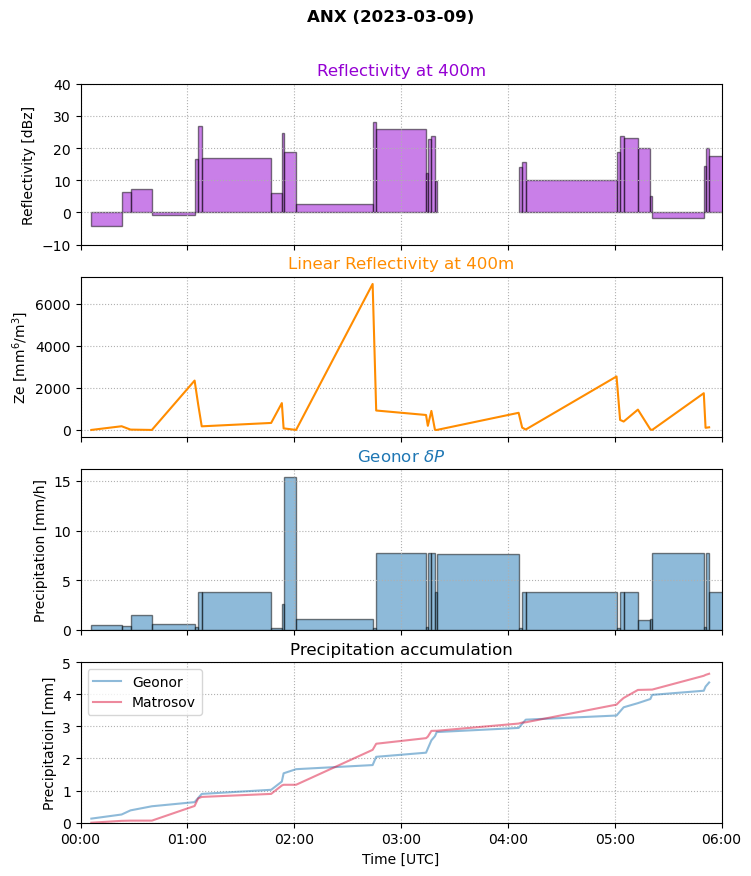

In [ ]:
# fig, axsm = plt.subplots(3,1, figsize=(8.27, 7.014), sharex=True)
fig, axsm = plt.subplots(4,1, figsize=(8.27, 7.014/3*4), sharex=True)
axs= axsm.flatten()

# compute time differences in days
dt = df_only.index.to_series().diff().dt.total_seconds().div(86400)
# shift so each bar uses the NEXT delta as width
widths = dt.shift(-1).fillna(dt.mean())  # last one: fallback to mean width


# Reflectivity in dbz at 400m
# axs[0].scatter(df_only['Ze_400m'].index, df_only['Ze_400m'], color='darkviolet', s=5)
axs[0].bar(df_only['Z_from_linear'].index, df_only['Ze_400m'], width=widths, align='edge', color='darkviolet', edgecolor='black', alpha=0.5)
axs[0].set_ylabel(f"Reflectivity [{ds_23['Ze_400m'].attrs['units']}]")
axs[0].set_yticks(np.arange(-10,50,10))

# Reflectitivyt in linear units at 400m
axs[1].plot(df_only['Ze_linear'].index, df_only['Ze_linear'], color='darkorange', )#s=5)
# axs[1].bar(df_only['Ze_linear'].index, df_only['Ze_linear'], color='darkorange',  width=widths, align='edge', edgecolor='black', alpha=0.5)
axs[1].set_ylabel("Ze [mm${^6}$/m${^3}$]")
# axs[1].set_yscale('log')


# Precip at Geonor
# plot bar
axs[2].bar(df_only.index, df_only['rate_mm_h'], width=widths, align='edge', color='tab:blue', alpha=0.5, edgecolor="black")
axs[2].set_ylabel("Precipitation [mm/h]")

# cumsum at Geonor and from Matrosov
pg = df_only['Geonor'].cumsum()
axs[3].plot(pg.index, pg, color='tab:blue', alpha=0.5, label='Geonor')
pm = df_only['Matrosov_aggregate'].cumsum()
axs[3].plot(pm.index, pm, color='crimson', alpha=0.5, label='Matrosov')
axs[3].set_ylabel("Precipitatioin [mm]")
axs[3].set_ylim([0, 5])
axs[3].legend()

# Shared formatting
date_form = DateFormatter("%H:00")
for ax, title, color in zip(axs, ["Reflectivity at 400m", "Linear Reflectivity at 400m", "Geonor $\delta P$", "Precipitation accumulation"], ['darkviolet', 'darkorange', 'tab:blue', 'black']):
        ax.set(xlabel = "", )
        ax.set_title(title, color=color)
        ax.grid(ls=':')
        ax.tick_params(axis='x', labelrotation=0)
        plt.setp(ax.get_xticklabels(), horizontalalignment="center")
        ax.xaxis_date()
        ax.xaxis.set_major_formatter(date_form)
        ax.set_xlim([day_start, _xmax])

axs[-1].set(xlabel="Time [UTC]")
fig.suptitle(f"{site.split('.')[0]} ({df_only.index[0].date()})", fontweight="bold")
# fig.subplots_adjust(top=0.94)
fig.subplots_adjust(top=0.9)

# save image to png
figname= os.path.join(FIG_DIR, 'reflectivity_400m', f'refl_dbz_mm6m3_geonor_matrosov_{site}_{df_only.index[0].date()}.png')
# plt.savefig(figname, format='png', bbox_inches='tight', dpi=300, )#transparent=True,)

### Plot the Ze_linear to mm/h for the case and then fill in with the rest of the data. Then add Z-S relationship fit and the one from Matrosov

In [ ]:
def model(x, a, b):
    return a * x**b

,Geonor,Matrosov_aggregate,Bracci_aggregate,Nakai_aggregate,Nakai_graupel,Pu_graupel,Ze_linear,air_temperature,wind_direction,wind_speed,Ze_400m,snowflake_class_name,Z_from_linear,delta_h,rate_mm_h
time,,,,,,,,,,,,,,,
2023-02-19 08:29:00,0.222100,0.004396,0.002372,0.005264,0.003359,0.004797,9.849524,0.847787,20.000000,4.600000,6.922955,aggregate,9.934152,0.033333,6.663000
2023-02-19 08:33:00,0.222300,0.013001,0.006893,0.013802,0.008808,0.011942,31.886695,0.755647,20.000000,3.850000,8.695259,aggregate,15.036095,0.066667,3.334500
2023-02-19 09:24:00,0.111200,0.001130,0.000666,0.002532,0.001616,0.003077,1.632605,1.178514,33.888889,7.855556,-5.248400,aggregate,2.128812,0.600000,0.185333
2023-02-19 09:33:00,0.111300,0.036861,0.018903,0.031833,0.020314,0.025706,108.428779,1.161513,36.666667,13.066667,7.528517,aggregate,20.351446,0.150000,0.742000
2023-02-19 10:25:00,0.111400,0.127358,0.064027,0.093891,0.059916,0.069402,409.827861,1.272596,34.166667,14.916667,14.005223,aggregate,26.126015,0.200000,0.557000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-03-12 13:39:00,0.132500,0.173560,0.085849,0.114228,0.072894,0.080333,605.672810,-2.300233,200.000000,7.200000,13.768612,aggregate,27.822381,0.200000,0.662500
2023-03-12 20:37:00,0.133200,0.133534,0.069603,0.131188,0.083717,0.113283,366.570856,-0.723968,189.298246,8.346930,4.605813,aggregate,25.641579,3.800000,0.035053
2023-03-13 01:07:00,0.133200,0.102416,0.051953,0.079973,0.051034,0.060378,313.928961,-2.226926,192.727273,5.500000,13.889895,aggregate,24.968314,0.183333,0.726545


In [ ]:
df_zs = df_corrected[["rate_mm_h", "Ze_linear"]].dropna()

In [ ]:
# Log-linear regressions ln(y) = ln(a) + b*ln(x) --> gives a straight line
logx = (np.where(df_zs["rate_mm_h"] >0, np.log(df_zs["rate_mm_h"]), np.nan))#np.log(df_zs["rate_mm_h"])
logy = (np.where(df_zs['Ze_linear'] >0, np.log(df_zs['Ze_linear']), np.nan)) #np.log(df_zs["Ze_linear"])

# Drop rows where either logx or logy is Nan
valid = (~np.isnan(logx)) & (~np.isnan(logy))
logx_clean = logx[valid]
logy_clean = logy[valid]


# Linear regression on log-log data
b2, loga = np.polyfit(logx_clean, logy_clean, 1)
a2 = np.exp(loga)

print(f"Fit: Z = {a2:.3f} * S^{b2:.3f}")

# Nonlinear curve fitting 
# the curve fitting is done with an iterative nonlinear optimization. The optimizer starts at the guess p0, then tries to minimize the squared error between the model and the data. A good initial guess helps the optimizer converge quickly and to get the right solution. 
# From the log-linear regression we get a quick estimate of a and b, that's why we use those as p0
params, cov = curve_fit(model, df_zs['rate_mm_h'], df_zs['Ze_linear'], p0=(a2,b2))
a, b = params
print(f"Fit: Z = {a:.3f} * S^{b:.3f}")

Fit: Z = 248.496 * S^-0.163
Fit: Z = 709.577 * S^-0.177


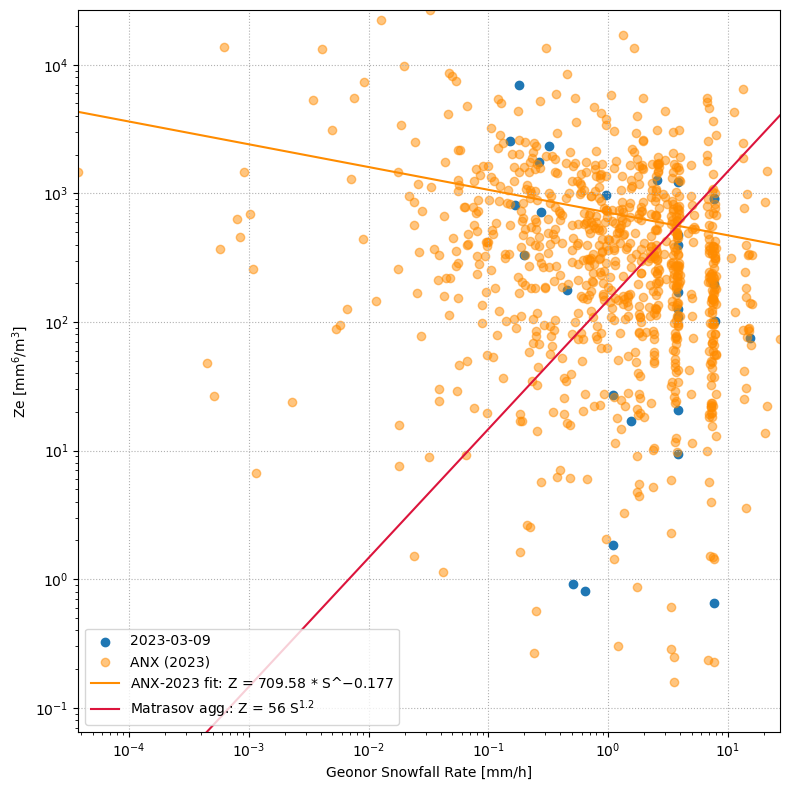

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(x=df_only['rate_mm_h'], y=df_only['Ze_linear'], color='tab:blue', label=f"{df_only.index[0].date()}")
ax.scatter(x=df_exclude['rate_mm_h'], y=df_exclude['Ze_linear'], color='darkorange', alpha=0.5, label=f"{site.split('.')[0]} (2023)")

# Plot trend line non-linear
x_smooth = np.linspace(df_corrected['rate_mm_h'].min(), df_corrected['Ze_linear'].max(),200)
y_smooth = model(x_smooth, a, b)
ax.plot(x_smooth, y_smooth, color='darkorange', label=f"ANX-2023 fit: Z = {a:.2f} * S^${{{b:.3f}}}$")


# Generate line for Matrosov
xfit = np.linspace(df_corrected["Matrosov_aggregate"].min(), df_corrected["Ze_linear"].max(), 200)
yfit = model(xfit, 56, 1.2)
plt.plot(xfit, yfit, color='crimson', label="Matrasov agg.: Z = 56 S$^{1.2}$")

# Set labels and title
ax.set_xlabel('Geonor Snowfall Rate [mm/h]')
ax.set_ylabel("Ze [mm$^{6}$/m$^{3}$]")
ax.grid(True, ls=':')
ax.set_yscale('log')
ax.set_xscale('log')
ax.legend()

ax.set_xlim(df_corrected['rate_mm_h'].min(), df_corrected['rate_mm_h'].max())
ax.set_ylim(df_corrected['Ze_linear'].min(), df_corrected['Ze_linear'].max())

plt.tight_layout()

figname = os.path.join(FIG_DIR, 'snowfall_rate', 'Z_S_2023_fit_matrosov.png')
# plt.savefig(figname, format='png', bbox_inches='tight', dpi=300) # transparent=True,

In [ ]:
df_sum_1h = df_sum.resample('1H').sum(numeric_only=True)
## Convert snowfall increments to rate (mm/h)
# Calculate time difference in hours
df_sum_1h["delta_h"] = df_sum_1h.index.to_series().diff().dt.total_seconds() / 3600

# Convert to mm/h rate
df_sum_1h["rate_mm_h"] = df_sum_1h["precipitation"] / df_sum_1h["delta_h"]

df_sum_1h

df_sum_1h['Ze_linear'] = df_sum['Ze_linear'].resample('1H').mean(numeric_only=True)

In [ ]:
df_sum_1h_nan = df_sum_1h[['rate_mm_h', 'Ze_linear', 'Matrosov_aggregate']].dropna()

In [ ]:
# Log-linear regressions ln(y) = ln(a) + b*ln(x) --> gives a straight line
logx = (np.where(df_sum_1h_nan["rate_mm_h"] >0, np.log(df_sum_1h_nan["rate_mm_h"]), np.nan))#np.log(df_sum_1h_nan["rate_mm_h"])
logy = (np.where(df_sum_1h_nan['Ze_linear'] >0, np.log(df_sum_1h_nan['Ze_linear']), np.nan)) #np.log(df_sum_1h_nan["Ze_linear"])

# Drop rows where either logx or logy is Nan
valid = (~np.isnan(logx)) & (~np.isnan(logy))
logx_clean = logx[valid]
logy_clean = logy[valid]


# Linear regression on log-log data
b2, loga = np.polyfit(logx_clean, logy_clean, 1)
a2 = np.exp(loga)

print(f"Fit: Z = {a2:.3f} * S^{b2:.3f}")

# Nonlinear curve fitting 
# the curve fitting is done with an iterative nonlinear optimization. The optimizer starts at the guess p0, then tries to minimize the squared error between the model and the data. A good initial guess helps the optimizer converge quickly and to get the right solution. 
# From the log-linear regression we get a quick estimate of a and b, that's why we use those as p0
params, cov = curve_fit(model, df_sum_1h_nan['rate_mm_h'], df_sum_1h_nan['Ze_linear'], p0=(a2,b2))
a, b = params
print(f"Fit: Z = {a:.3f} * S^{b:.3f}")

Fit: Z = 65.941 * S^0.400
Fit: Z = 145.760 * S^0.485


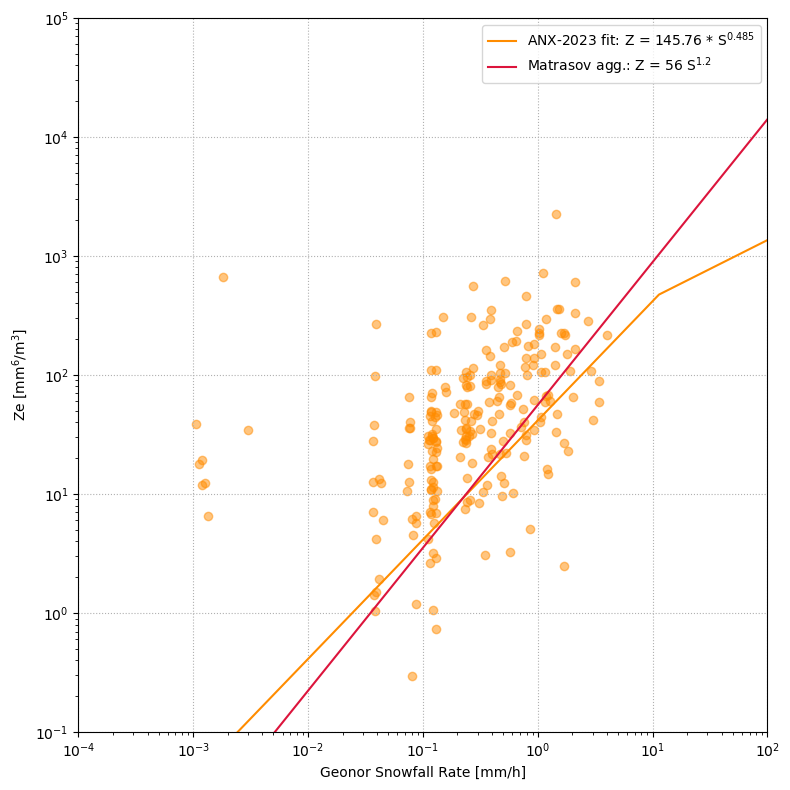

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(x=df_sum_1h_nan['rate_mm_h'], y=df_sum_1h_nan['Ze_linear'], color='darkorange', alpha=0.5)
# ax.scatter(x=df_exclude['rate_mm_h'], y=df_exclude['Ze_linear'], color='darkorange', alpha=0.5, label=f"{site.split('.')[0]} (2023)")

# Plot trend line non-linear
x_smooth = np.linspace(df_sum_1h_nan['rate_mm_h'].min(), df_sum_1h_nan['Ze_linear'].max(),200)
y_smooth = model(x_smooth, a, b)
ax.plot(x_smooth, y_smooth, color='darkorange', label=f"ANX-2023 fit: Z = {a:.2f} * S$^{{{b:.3f}}}$")


# Generate line for Matrosov
xfit = np.linspace(df_sum_1h_nan["Matrosov_aggregate"].min(), df_sum_1h_nan["Ze_linear"].max(), 200)
yfit = model(xfit, 56, 1.2)
plt.plot(xfit, yfit, color='crimson', label="Matrasov agg.: Z = 56 S$^{1.2}$")

# Set labels and title
ax.set_xlabel('Geonor Snowfall Rate [mm/h]')
ax.set_ylabel("Ze [mm$^{6}$/m$^{3}$]")
ax.grid(True, ls=':')
ax.set_yscale('log')
ax.set_xscale('log')
ax.legend()

# ax.set_xlim(df_sum_1h_nan['rate_mm_h'].min(), df_sum_1h_nan['rate_mm_h'].max())
# ax.set_ylim(df_sum_1h_nan['Ze_linear'].min(), df_sum_1h_nan['Ze_linear'].max())
ax.set_xlim([10**(-4), 10**2])
ax.set_ylim([10**(-1), 10**5])

plt.tight_layout()

figname = os.path.join(FIG_DIR, 'snowfall_rate', 'Zmean_S_2023_fit_geonor_matrosov_1h.png')
plt.savefig(figname, format='png', bbox_inches='tight', dpi=300) # transparent=True,

In [ ]:
df_aggregate = df_corrected.loc[df_corrected['snowflake_class_name'] == 'aggregate', ]#.resample('1H').sum()
df_graupel = df_corrected.loc[df_corrected['snowflake_class_name'] == 'graupel', ]#.resample('1H').sum()
df_pristine = df_corrected.loc[df_corrected['snowflake_class_name'] == 'pristine']#.resample('1H').sum()
df_mixed = df_corrected.loc[df_corrected['snowflake_class_name'] == 'mixed']#.resample('1H').sum()

In [ ]:
def get_a_b_curve_fit_for_ZS(df):

    # Log-linear regressions ln(y) = ln(a) + b*ln(x) --> gives a straight line
    logx = (np.where(df["rate_mm_h"] >0, np.log(df["rate_mm_h"]), np.nan))#np.log(df["rate_mm_h"])
    logy = (np.where(df['Ze_linear'] >0, np.log(df['Ze_linear']), np.nan)) #np.log(df["Ze_linear"])

    # Drop rows where either logx or logy is Nan
    valid = (~np.isnan(logx)) & (~np.isnan(logy))
    logx_clean = logx[valid]
    logy_clean = logy[valid]


    # Linear regression on log-log data
    b2, loga = np.polyfit(logx_clean, logy_clean, 1)
    a2 = np.exp(loga)

    print(f"Fit: Z = {a2:.3f} * S^{b2:.3f}")

    # Nonlinear curve fitting 
    # the curve fitting is done with an iterative nonlinear optimization. The optimizer starts at the guess p0, then tries to minimize the squared error between the model and the data. A good initial guess helps the optimizer converge quickly and to get the right solution. 
    # From the log-linear regression we get a quick estimate of a and b, that's why we use those as p0
    params, cov = curve_fit(model, df['rate_mm_h'], df['Ze_linear'], p0=(a2,b2))
    a, b = params
    print(f"Fit: Z = {a:.3f} * S^{b:.3f}")

    return(a, b)

In [ ]:
a_agg, b_agg = get_a_b_curve_fit_for_ZS(df_aggregate)

Fit: Z = 264.816 * S^-0.136
Fit: Z = 264.816 * S^-0.136


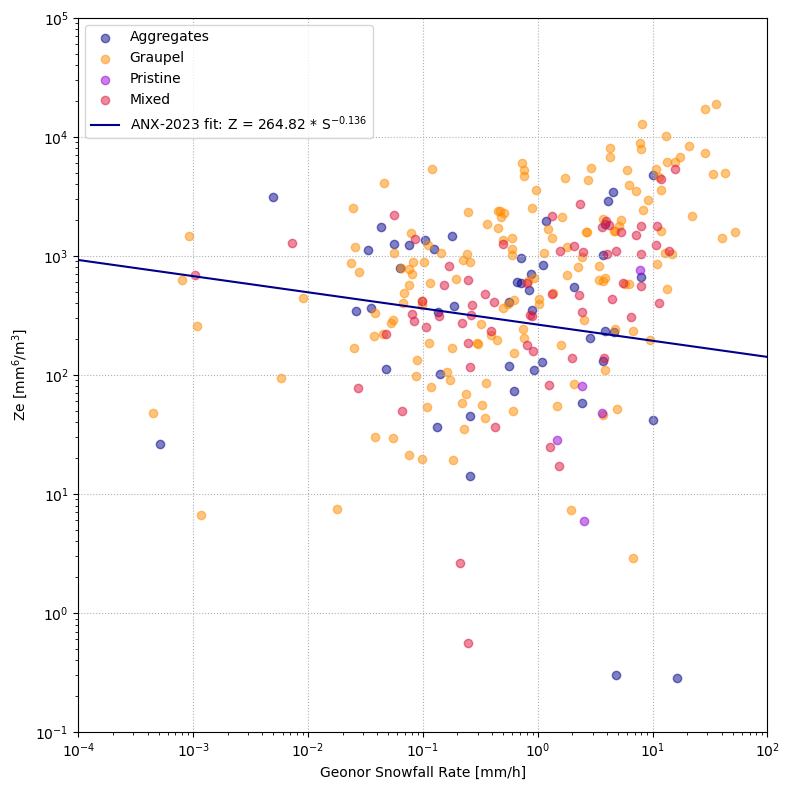

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(x=df_aggregate['rate_mm_h'], y=df_aggregate['Ze_linear'], color='darkblue', alpha=0.5, label="Aggregates")
ax.scatter(x=df_graupel['rate_mm_h'], y=df_graupel['Ze_linear'], color='darkorange', alpha=0.5, label="Graupel")
ax.scatter(x=df_pristine['rate_mm_h'], y=df_pristine['Ze_linear'], color='darkviolet', alpha=0.5, label="Pristine")
ax.scatter(x=df_mixed['rate_mm_h'], y=df_mixed['Ze_linear'], color='crimson', alpha=0.5, label="Mixed")



# Plot trend line non-linear
x_smooth = np.linspace(10**(-4), 10**5,200)
y_smooth = model(x_smooth, a_agg, b_agg)
ax.plot(x_smooth, y_smooth, color='darkblue', label=f"ANX-2023 fit: Z = {a_agg:.2f} * S$^{{{b_agg:.3f}}}$")


# # Generate line for Matrosov
# xfit = np.linspace(df_corrected["Matrosov_aggregate"].min(), df_corrected["Ze_linear"].max(), 200)
# yfit = model(xfit, 56, 1.2)
# plt.plot(xfit, yfit, color='crimson', label="Matrasov agg.: Z = 56 S$^{1.2}$")

# Set labels and title
ax.set_xlabel('Geonor Snowfall Rate [mm/h]')
ax.set_ylabel("Ze [mm$^{6}$/m$^{3}$]")
ax.grid(True, ls=':')
ax.set_yscale('log')
ax.set_xscale('log')
ax.legend()

ax.set_xlim([10**(-4), 10**2])
ax.set_ylim([10**(-1), 10**5])

plt.tight_layout()

figname = os.path.join(FIG_DIR, 'snowfall_rate', 'Z_S_2023_fit_snowflake_class_name.png')
# plt.savefig(figname, format='png', bbox_inches='tight', dpi=300) # transparent=True,

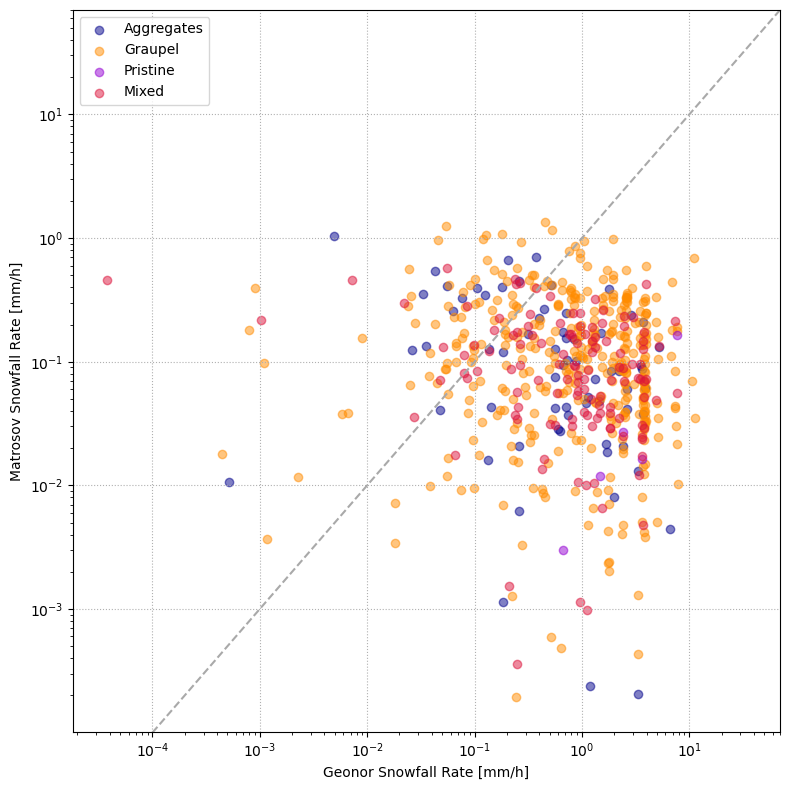

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(x=df_aggregate['rate_mm_h'], y=df_aggregate['Matrosov_aggregate'], color='darkblue', alpha=0.5, label="Aggregates")
ax.scatter(x=df_graupel['rate_mm_h'], y=df_graupel['Matrosov_aggregate'], color='darkorange', alpha=0.5, label="Graupel")
ax.scatter(x=df_pristine['rate_mm_h'], y=df_pristine['Matrosov_aggregate'], color='darkviolet', alpha=0.5, label="Pristine")
ax.scatter(x=df_mixed['rate_mm_h'], y=df_mixed['Matrosov_aggregate'], color='crimson', alpha=0.5, label="Mixed")

x = np.linspace(0, 10**2, 100)
y = x

ax.plot(x, y, linestyle='--', color='darkgrey')

# Set labels and title
ax.set_xlabel('Geonor Snowfall Rate [mm/h]')
ax.set_ylabel("Matrosov Snowfall Rate [mm/h]")
ax.grid(True, ls=':')
ax.set_yscale('log')
ax.set_xscale('log')
ax.legend()

ax.set_xlim([0, 7*10**1])
ax.set_ylim([0, 7*10**1])

plt.tight_layout()
figname = os.path.join(FIG_DIR, 'snowfall_rate', 'Geonor_Matrosov_snowflake_class_name.png')
# plt.savefig(figname, format='png', bbox_inches='tight', dpi=300) # transparent=True,

In [ ]:
## Bin averaging
        # create new dataset with time resolution 1 minute to
        _time = pd.date_range(day_start, periods=1440, freq="min").strftime('%Y-%m-%dT%H:%M:%S')
        dsm = xr.Dataset(data_vars=dict(
                                        air_temperature=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_direction=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_speed=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        precipitation=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        Ze=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),
                                        W=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),
                                        height=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),
                                        spectralWidth=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),),
                        coords=dict(time=_time, range=dsx.range[1:-1][::2].values))
        # assign variables and attributes to the dataset
        dsm['time'] = pd.to_datetime(dsm.time)

        # averaged values for each bin, return dataset
        dsm = fct.MRR_bin_averaged_dataset(dsx, dsm)

        # add MetNo data to dataset
        dsm['air_temperature'] = dsx['air_temperature']
        dsm['wind_direction'] = dsx['wind_direction']
        dsm['wind_speed'] = dsx['wind_speed']
        # dsm['precipitation'] = dsx['precipitation']


        fct.plt_Ze_W_p_T_U(dsm, day_start, _xmax, key)
        # save image to png
        plt.savefig(FIG_DIR + 'bin_avg_{}'.format(figname), format='png', bbox_inches='tight', transparent=True)

        # rename variables to indicate mean values
        dsm = dsm.rename({'range':'mean_range', 'Ze':'Ze_mean', 'W':'W_mean', 'height':'height_mean', 'spectralWidth':'spectralWidth_mean'})
        ###########################################################

        # merge original dataset with mean dataset
        dsx = dsx.merge(other=dsm, fill_value=np.nan, combine_attrs='no_conflicts')        


        # print("writing...", file_out)
        # dsx.to_netcdf(file_out)


In [ ]:
## Create TinyTag Temperature files with same time res as MRR data
# ds = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'MRR_islas/bin_averaged/*'))))['time']
# ds_T = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'islas_met_obs/*'))))
# years 
# months=['03']
# days=np.arange(18,22)
# years, months, days


# for day in days:
#     time = '{}-{}-{}'.format(years[0], months[0], day)
#     print(time)
    
#     TA = ds_T['TA'].where(ds.sel(time=time))
    
#     TA2 = TA.interp(time=ds.sel(time=time))
    
#     TA.plot()
#     TA2.plot()
    
#     TA2.to_netcdf('TinyTag_T_ISLAS{}{}{}.nc'.format(years[0], months[0], day))


In [ ]:
# rsync -a --progress franzihe@mimi.uio.no:/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity /uufs/chpc.utah.edu/common/home/u6030275/public_html/Figures

In [ ]:
# rsync -av --progress franzihe@mimi.uio.no:/scratch/franzihe/output/MRR_islas /uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data/


In [ ]:
# rsync -a --progress login.nird.sigma2.no:/projects/NS9600K/sldam/timelapses_islas2022 /home/franzihe/Documents/Figures

In [ ]:
# files = sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*')))
# # metno = xr.open_dataset('/scratch/franzihe/input/Met-No_obs/SN87110/sum(precipitation_amount PT1H)_202203.nc')
# metno = xr.open_mfdataset(files)

# f, ax = plt.subplots(figsize=[3.18, 5.25], ) 
# (metno.sel(time='2022-04-01')['sum(precipitation_amount PT1H)'].cumsum(dim='time') - metno.sel(time='2022-04-01')['sum(precipitation_amount PT1H)'].isel(time=0)).plot.line(ax =ax, x='time', 
#                                                                                             ylim=[0,20], 
#                                                                                             xlim=['2022-04-01T00:00:00.000000000', '2022-04-02T00:00:00.000000000'],
#                                                                                             label='MetNo obs',add_legend=True)

# # plot legend
# ax.legend(loc='upper right')
# ax.set_ylabel('', )#fontsize = 10.0) # Y label
# ax.set_xlabel('', )#fontsize = 10) # X label

# ax.set_xticklabels([])
# ax.set_yticklabels([])
# ax.grid(True)

# plt.savefig('demo.png', transparent=True)